# 2. SPRINT 1 — Comprensión del negocio y comprensión de datos

**Proyecto de investigación:** *Modelo predictivo de horas de indisponibilidad operativa mediante Gradient Boosting Machine (GBM) considerando variables meteorológicas y oceanográficas en el Terminal Portuario ENGIE Perú, Ilo.*

**Marco metodológico:** CRISP-DM · **Marco de gestión:** Scrum · **Sprint:** Sprint 1 — Semanas 1 a 6 · **Épica:** Comprensión del negocio y de los datos

**Estructura del notebook**

| N.° | Historia de usuario / Tarea | Contenido |
|---|---|---|
| 2.1 | **HU01** — Definición del problema predictivo | |
| 2.1.1 | T01 | Identificar el problema de negocio del Terminal Portuario ENGIE-Ilo (**2 story points**) |
| 2.1.2 | T02 | Definir las variables objetivo: inicio y duración de la indisponibilidad operativa dentro de un horizonte de 24 h (**3 story points**) |
| 2.2 | **HU02** — Definición de métricas del modelo | |
| 2.2.1 | T03 | Definir métricas de evaluación: RMSE, MAPE, MAE y R² |
| 2.3 | **HU03** — Integración de fuentes de datos | |
| 2.3.1 | T04 | Importar datos meteorológicos |
| 2.3.2 | T05 | Importar datos oceanográficos |
| 2.3.3 | T06 | Integrar historiales de indisponibilidad operativa |
| 2.4 | **HU04** — Análisis exploratorio de datos | |
| 2.4.1 | T07 | Realizar análisis descriptivo y correlacional |
| 2.4.2 | T08 | Identificar valores faltantes y outliers |

> **Alcance (T02):** el histórico disponible no solo registra el total de horas de indisponibilidad, sino la **fecha de inicio y la fecha de fin de cada evento**. Por ello, en lugar de una única salida agregada, el modelo estimará **dos variables objetivo relacionadas con el próximo evento dentro del horizonte de 24 h**: (1) cuánto falta para que inicie y (2) cuánto durará. El fin del evento se deriva de ambas, no se modela directamente.

> **Datos:** este notebook trabaja únicamente con los **datos** del terminal (CSV del datalogger e histórico de indisponibilidad).

### Preparación del entorno (estilo y funciones de dibujo compartidas)

In [ ]:
# ==== Configuración visual compartida por los diagramas de este notebook ====
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle

COLOR_NAVY    = '#1B3A5C'   # estructura / texto principal
COLOR_TEAL    = '#2A9D8F'   # disponible / cumplido / predictor
COLOR_TEAL_LT = '#D6EFEC'
COLOR_ORANGE  = '#E9762B'   # pendiente / validar con negocio
COLOR_RED     = '#C43D3D'   # riesgo / prohibido (data leakage)
COLOR_GRAY    = '#9AA5B1'   # fuera de alcance / derivado
COLOR_GRAY_LT = '#EEF1F4'
COLOR_GOLD    = '#E3A857'   # evento / indisponibilidad

plt.rcParams['font.family'] = 'DejaVu Sans'

def caja(ax, x, y, w, h, texto, color=COLOR_NAVY, texto_color='white',
         fontsize=10.5, fontweight='bold'):
    """Dibuja un recuadro redondeado con texto centrado."""
    box = FancyBboxPatch((x, y), w, h,
                          boxstyle='round,pad=0.02,rounding_size=0.05',
                          linewidth=1.5, edgecolor=color, facecolor=color, zorder=2)
    ax.add_patch(box)
    ax.text(x + w/2, y + h/2, texto, ha='center', va='center',
            fontsize=fontsize, color=texto_color, fontweight=fontweight,
            zorder=3, linespacing=1.35)
    return box

def flecha(ax, p1, p2, color=COLOR_NAVY, lw=1.8, style='-|>', rad=0.0):
    """Dibuja una flecha curva/recta entre dos puntos."""
    arr = FancyArrowPatch(p1, p2, arrowstyle=style, mutation_scale=15,
                           color=color, lw=lw,
                           connectionstyle=f'arc3,rad={rad}', zorder=1)
    ax.add_patch(arr)

def lienzo(w=11, h=5, xlim=(0, 11), ylim=(0, 5)):
    """Crea una figura/ejes en blanco (sin bordes) del tamaño indicado."""
    fig, ax = plt.subplots(figsize=(w, h))
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.axis('off')
    return fig, ax


## 2.1 HU01 — Definición del problema predictivo

**Historia de usuario formalizada:**
*Como investigador, quiero definir el problema de predicción del inicio y la duración de la indisponibilidad operativa del Terminal Portuario ENGIE-Ilo, para establecer claramente el objetivo del modelo de Machine Learning.*

### Criterios de aceptación propuestos para HU01

1. El problema de negocio debe estar descrito sin confundirlo con la solución tecnológica.
2. Debe documentarse el proceso actual (*As-Is*) que evidencia la necesidad de anticipación.
3. La necesidad empresarial debe traducirse a un problema analítico explícito.
4. **Las dos variables objetivo** (inicio y duración) deben tener definición semántica, unidad, tipo estadístico, temporalidad y fuente.
5. Deben quedar identificadas las decisiones abiertas que requieren validación de un experto de Operaciones, incluyendo el manejo de horizontes sin evento y de eventos múltiples.
6. La definición debe ser compatible con la secuencia temporal del proyecto y evitar el uso de información futura como predictor (*data leakage*).


### Ficha del proyecto

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

pd.set_option('display.max_colwidth', 160)

proyecto = {
    'Organización / caso de estudio': 'Terminal Portuario ENGIE-Ilo',
    'Tipo de investigación': 'Aplicada - analítica predictiva',
    'Metodología de datos': 'CRISP-DM',
    'Marco de gestión': 'Scrum',
    'Sprint': 'Sprint 1 - Comprensión del negocio y comprensión de datos',
    'Historia de usuario': 'HU01 - Definición del problema predictivo',
    'Tarea 1': 'T01 - Identificación del problema de negocio',
    'Tarea 2': 'T02 - Definición de las variables objetivo (inicio y duración)',
    'Unidad temporal base': '1 hora',
    'Horizonte de predicción': '24 horas hacia adelante (t, t+24h] — el evento ocurre DENTRO de esta ventana',
    'Tipo de problema ML': 'Regresión supervisada (doble salida) + clasificación auxiliar de ocurrencia',
    'Variable objetivo 1': 'Horas desde t hasta el inicio del próximo evento de indisponibilidad (horas_hasta_inicio_24h)',
    'Variable objetivo 2': 'Duración del evento de indisponibilidad en horas (duracion_indisponibilidad_h)',
    'Variable derivada (no modelada)': 'Hora de fin del evento = t + horas_hasta_inicio_24h + duracion_indisponibilidad_h',
    'Familia de algoritmos planificada': 'GBM — Gradient Boosting (XGBoost, LightGBM) y variantes (Random Forest como referencia)'
}

display(pd.DataFrame(proyecto.items(), columns=['Elemento', 'Definición']))


,Elemento,Definición
0,Organización / caso de estudio,Terminal Portuario ENGIE-Ilo
1,Tipo de investigación,Aplicada - analítica predictiva
2,Metodología de datos,CRISP-DM
3,Marco de gestión,Scrum
4,Sprint,Sprint 1 - Comprensión del negocio y comprensión de datos
5,Historia de usuario,HU01 - Definición del problema predictivo
6,Tarea 1,T01 - Identificación del problema de negocio
7,Tarea 2,T02 - Definición de las variables objetivo (inicio y duración)
8,Unidad temporal base,1 hora
9,Horizonte de predicción,"24 horas hacia adelante (t, t+24h] — el evento ocurre DENTRO de esta ventana"


### Vista rápida: la idea completa en un solo gráfico

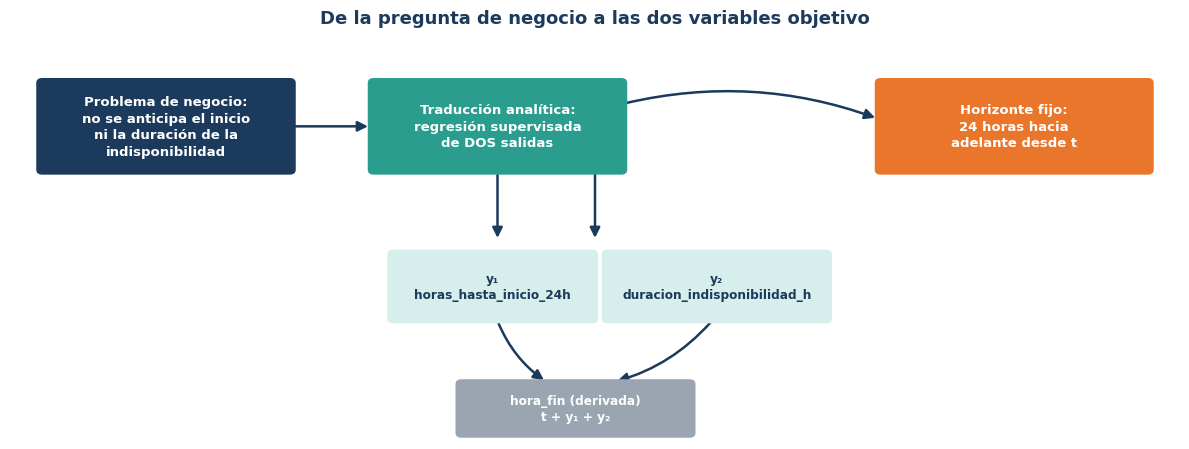

In [ ]:
fig, ax = lienzo(12, 4.6, xlim=(0, 12), ylim=(0, 5.2))
ax.set_title('De la pregunta de negocio a las dos variables objetivo', fontsize=13,
             color=COLOR_NAVY, fontweight='bold', pad=14)

caja(ax, 0.3, 3.5, 2.6, 1.2, 'Problema de negocio:\nno se anticipa el inicio\nni la duración de la\nindisponibilidad', color=COLOR_NAVY, fontsize=9.5)
flecha(ax, (2.9, 4.1), (3.7, 4.1))
caja(ax, 3.7, 3.5, 2.6, 1.2, 'Traducción analítica:\nregresión supervisada\nde DOS salidas', color=COLOR_TEAL, fontsize=9.5)
flecha(ax, (5.0, 3.5), (5.0, 2.6))
flecha(ax, (6.0, 3.5), (6.0, 2.6))

caja(ax, 3.9, 1.55, 2.1, 0.9, 'y\u2081\nhoras_hasta_inicio_24h', color=COLOR_TEAL_LT, texto_color=COLOR_NAVY, fontsize=8.7)
caja(ax, 6.1, 1.55, 2.3, 0.9, 'y\u2082\nduracion_indisponibilidad_h', color=COLOR_TEAL_LT, texto_color=COLOR_NAVY, fontsize=8.7)

flecha(ax, (5.0, 1.55), (5.5, 0.75), rad=0.15)
flecha(ax, (7.2, 1.55), (6.2, 0.75), rad=-0.15)
caja(ax, 4.6, 0.05, 2.4, 0.7, 'hora_fin (derivada)\nt + y\u2081 + y\u2082', color=COLOR_GRAY, fontsize=8.7)

caja(ax, 8.9, 3.5, 2.8, 1.2, 'Horizonte fijo:\n24 horas hacia\nadelante desde t', color=COLOR_ORANGE, fontsize=9.5)
flecha(ax, (6.3, 4.4), (8.9, 4.2), rad=-0.15)

plt.tight_layout()
plt.show()


### Ubicación de HU01 dentro de CRISP-DM

CRISP-DM organiza el trabajo analítico en fases iterativas. En nuestro proyecto, HU01 pertenece principalmente a **Comprensión del Negocio**, porque antes de manipular datos o entrenar modelos es necesario establecer **qué decisión empresarial se desea mejorar**, **qué fenómeno será predicho** y **cómo se expresará cuantitativamente el resultado esperado**.

La relación con **Comprensión de los Datos** en este punto es deliberadamente limitada: solo se registra qué fuentes deben existir para hacer viable la predicción y qué restricciones temporales presentan. La importación, integración y exploración detallada corresponden a HU03 y HU04. Sin embargo, en esta versión de HU01 que presentamos,sí se deja establecida la **estructura de las fuentes** (variables meteo-oceanográficas por archivo y registro histórico de eventos con inicio/fin), porque de ella depende directamente cómo se construyen las dos variables objetivo.


In [ ]:
crisp_dm_hu01 = pd.DataFrame([
    ['Comprensión del negocio', 'Objetivos del negocio', 'Determinar qué problema operativo necesita anticipación', 'T01'],
    ['Comprensión del negocio', 'Objetivo de minería de datos', 'Traducir la necesidad operativa a un problema de regresión de doble salida (inicio y duración)', 'T01'],
    ['Comprensión del negocio', 'Criterio analítico', 'Definir qué dos resultados numéricos se desea estimar y cómo se deriva el fin del evento', 'T02'],
    ['Comprensión del negocio', 'Restricciones', 'Fijar unidad temporal, horizonte (evento dentro de 24h) y reglas de las dos etiquetas', 'T02'],
    ['Comprensión de los datos', 'Inventario inicial', 'Identificar archivos CSV de variables meteo-oceanográficas y el histórico de eventos con inicio/fin', 'Puente hacia HU03'],
])
crisp_dm_hu01.columns = ['Fase CRISP-DM', 'Componente', 'Aplicación al proyecto', 'Trazabilidad']
display(crisp_dm_hu01)


,Fase CRISP-DM,Componente,Aplicación al proyecto,Trazabilidad
0,Comprensión del negocio,Objetivos del negocio,Determinar qué problema operativo necesita anticipación,T01
1,Comprensión del negocio,Objetivo de minería de datos,Traducir la necesidad operativa a un problema de regresión de doble salida (inicio y duración),T01
2,Comprensión del negocio,Criterio analítico,Definir qué dos resultados numéricos se desea estimar y cómo se deriva el fin del evento,T02
3,Comprensión del negocio,Restricciones,"Fijar unidad temporal, horizonte (evento dentro de 24h) y reglas de las dos etiquetas",T02
4,Comprensión de los datos,Inventario inicial,Identificar archivos CSV de variables meteo-oceanográficas y el histórico de eventos con inicio/fin,Puente hacia HU03


**Vista visual**

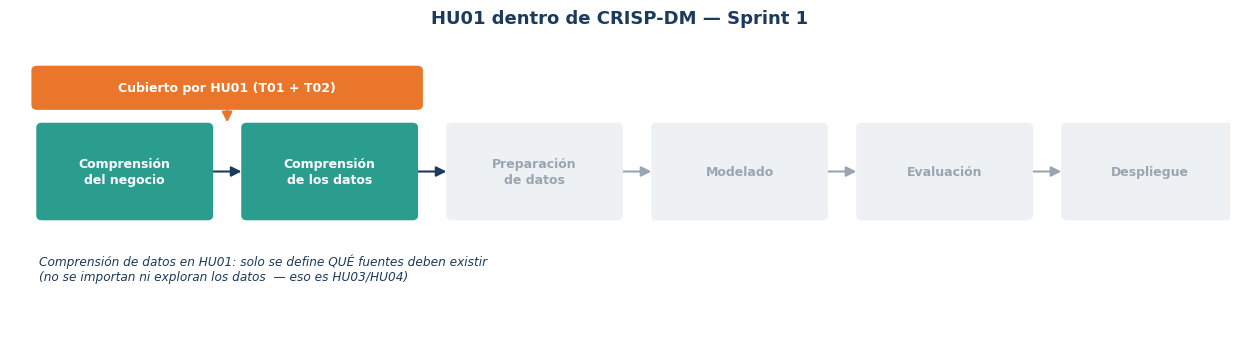

In [ ]:
fases = ['Comprensión\ndel negocio', 'Comprensión\nde los datos', 'Preparación\nde datos', 'Modelado', 'Evaluación', 'Despliegue']
activo = [True, True, False, False, False, False]

fig, ax = lienzo(12.5, 3.6, xlim=(0, 12.5), ylim=(0, 4.2))
ax.set_title('HU01 dentro de CRISP-DM — Sprint 1', fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=12)

n = len(fases)
w, gap = 1.75, 0.35
x0 = 0.3
for i, (f, a) in enumerate(zip(fases, activo)):
    x = x0 + i * (w + gap)
    color = COLOR_TEAL if a else COLOR_GRAY_LT
    tcolor = 'white' if a else COLOR_GRAY
    caja(ax, x, 1.7, w, 1.3, f, color=color, texto_color=tcolor, fontsize=9)
    if i < n - 1:
        flecha(ax, (x + w, 2.35), (x + w + gap, 2.35), color=COLOR_NAVY if a else COLOR_GRAY, lw=1.5)

caja(ax, x0 - 0.05, 3.25, 2*w + gap + 0.1, 0.55, 'Cubierto por HU01 (T01 + T02)', color=COLOR_ORANGE, fontsize=9)
flecha(ax, (x0 + (2*w + gap)/2, 3.25), (x0 + (2*w + gap)/2, 3.0), color=COLOR_ORANGE, lw=1.6)

ax.text(x0, 1.2, 'Comprensión de datos en HU01: solo se define QUÉ fuentes deben existir\n(no se importan ni exploran los datos  — eso es HU03/HU04)',
        fontsize=8.7, color=COLOR_NAVY, ha='left', va='top', style='italic')

plt.tight_layout()
plt.show()


### 2.1.1 T01 — Identificar el problema de negocio del Terminal Portuario ENGIE-Ilo

#### 2.1.1.1 Contexto operativo relevante

El Terminal Portuario ENGIE-Ilo opera en un entorno costero expuesto a variaciones **meteorológicas y oceanográficas**. Contamos con variables relevantes: la velocidad y dirección del viento, temperatura, humedad, presión atmosférica y oleaje. Estas condiciones pueden restringir temporalmente maniobras, suspender operaciones y generar períodos de indisponibilidad.

La necesidad no surge porque el terminal carezca de observación del entorno. El problema central es que el proceso actual es predominantemente **reactivo**: el personal observa las condiciones, comunica una alerta, se decide la suspensión cuando la afectación ya se manifiesta y luego se espera hasta que las condiciones mejoren. **El inicio y la duración de la indisponibilidad se conocen recién después del evento**, cuando se registran manualmente.

##### Proceso actual (*As-Is*) resumido

1. Observación empírica de oleaje y viento por personal de campo.
2. Comunicación de la condición al supervisor o jefe de Operaciones.
3. Decisión reactiva de suspensión de la maniobra.
4. Espera y seguimiento hasta la mejora de las condiciones.
5. Reanudación de la maniobra.
6. Registro manual del **inicio, fin y duración** de la indisponibilidad.

El punto crítico para esta investigación se ubica entre los pasos 2 y 4: **no existe una estimación anticipada de cuándo empezará la indisponibilidad ni de cuánto podría durar**.


**Vista visual — el proceso reactivo actual:**

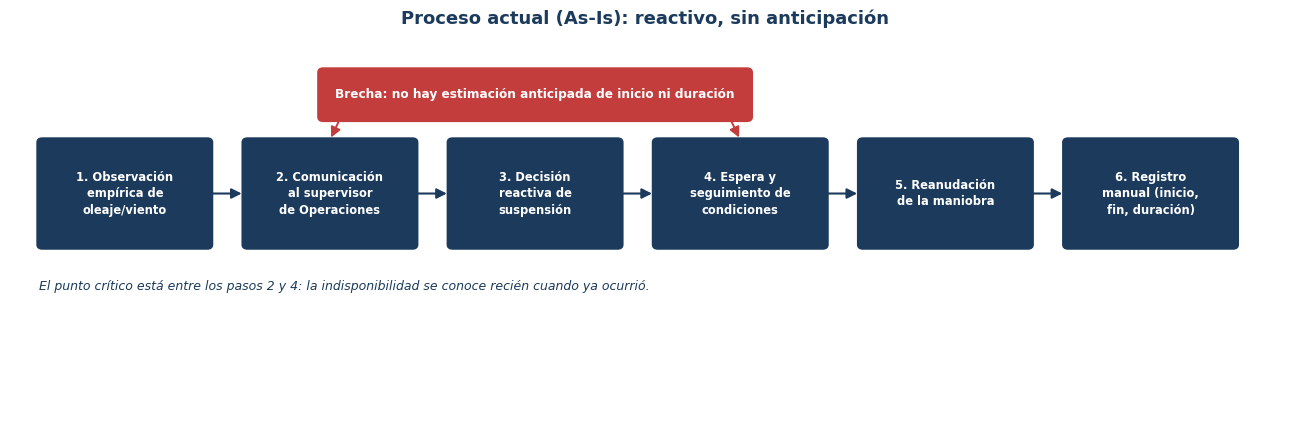

In [ ]:
pasos = ['1. Observación\nempírica de\noleaje/viento', '2. Comunicación\nal supervisor\nde Operaciones',
         '3. Decisión\nreactiva de\nsuspensión', '4. Espera y\nseguimiento de\ncondiciones',
         '5. Reanudación\nde la maniobra', '6. Registro\nmanual (inicio,\nfin, duración)']

fig, ax = lienzo(13, 4.4, xlim=(0, 13), ylim=(0, 4.6))
ax.set_title('Proceso actual (As-Is): reactivo, sin anticipación', fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=12)

n = len(pasos)
w, gap = 1.75, 0.35
x0 = 0.3
for i, p in enumerate(pasos):
    x = x0 + i * (w + gap)
    caja(ax, x, 2.1, w, 1.3, p, color=COLOR_NAVY, fontsize=8.3)
    if i < n - 1:
        flecha(ax, (x + w, 2.75), (x + w + gap, 2.75), color=COLOR_NAVY, lw=1.5)

x_ini = x0 + 1*(w + gap) + w*0.5
x_fin = x0 + 3*(w + gap) + w*0.5
caja(ax, x_ini - 0.1, 3.65, (x_fin - x_ini) + 0.2, 0.6, 'Brecha: no hay estimación anticipada de inicio ni duración', color=COLOR_RED, fontsize=8.7)
flecha(ax, (x_ini + 0.1, 3.65), (x0 + 1*(w + gap) + w/2, 3.4), color=COLOR_RED, lw=1.4)
flecha(ax, (x_fin - 0.1, 3.65), (x0 + 3*(w + gap) + w/2, 3.4), color=COLOR_RED, lw=1.4)

ax.text(x0, 1.7, 'El punto crítico está entre los pasos 2 y 4: la indisponibilidad se conoce recién cuando ya ocurrió.',
        fontsize=9, color=COLOR_NAVY, ha='left', va='top', style='italic')

plt.tight_layout()
plt.show()


#### 2.1.1.2 Formulación del problema de negocio

> **Problema de negocio:** El Terminal Portuario ENGIE-Ilo presenta una capacidad limitada para anticipar **el momento de inicio y la duración** de los períodos de indisponibilidad operativa asociados a condiciones meteorológicas y oceanográficas adversas. Como consecuencia, la planificación de maniobras, la asignación de recursos y la continuidad de las operaciones se gestionan con menor anticipación de la deseable y bajo un esquema principalmente reactivo.

Esta formulación evita definir prematuramente un algoritmo. El problema empresarial es **la falta de anticipación útil para planificar** (cuándo y por cuánto tiempo); Machine Learning es la alternativa tecnológica que la investigación evaluará posteriormente.

##### Impacto operativo esperado del problema

- Incertidumbre para programar actividades y ventanas operativas.
- Dificultad para asignar recursos con anticipación.
- Riesgo de tiempos improductivos durante suspensiones.
- Menor capacidad para coordinar decisiones preventivas frente a condiciones adversas.
- Dependencia elevada de observación y experiencia inmediata del personal.


In [ ]:
matriz_problema = pd.DataFrame([
    ['Condiciones ambientales', 'Variaciones de viento, oleaje y variables atmosféricas', 'Pueden restringir o suspender maniobras'],
    ['Proceso actual', 'Observación y decisión predominantemente reactiva', 'La respuesta se activa cuando la condición ya afecta la operación'],
    ['Brecha de información', 'No se dispone de una estimación previa de inicio ni de duración', 'La planificación futura queda limitada en dos dimensiones: cuándo y por cuánto tiempo'],
    ['Dato histórico', 'Se registran fecha de inicio y fecha de fin de cada evento (la duración se deriva de ambas)', 'Existe base suficiente para construir DOS etiquetas predictivas, no solo una agregada'],
    ['Necesidad de negocio', 'Anticipar cuándo iniciará y cuánto durará la indisponibilidad', 'Apoyar programación, asignación de recursos y toma de decisiones']
], columns=['Dimensión', 'Situación identificada', 'Implicancia'])

display(matriz_problema)


,Dimensión,Situación identificada,Implicancia
0,Condiciones ambientales,"Variaciones de viento, oleaje y variables atmosféricas",Pueden restringir o suspender maniobras
1,Proceso actual,Observación y decisión predominantemente reactiva,La respuesta se activa cuando la condición ya afecta la operación
2,Brecha de información,No se dispone de una estimación previa de inicio ni de duración,La planificación futura queda limitada en dos dimensiones: cuándo y por cuánto tiempo
3,Dato histórico,Se registran fecha de inicio y fecha de fin de cada evento (la duración se deriva de ambas),"Existe base suficiente para construir DOS etiquetas predictivas, no solo una agregada"
4,Necesidad de negocio,Anticipar cuándo iniciará y cuánto durará la indisponibilidad,"Apoyar programación, asignación de recursos y toma de decisiones"


#### 2.1.1.3 Pregunta de investigación y traducción al problema analítico

La formulación de investigación del documento base es:

> **¿De qué manera un modelo basado en Machine Learning, considerando variables meteorológicas, podría predecir las horas de indisponibilidad operativa en el Terminal Portuario ENGIE Perú, Ilo?**

Dado que el histórico permite conocer inicio y fin de cada evento (no solo el total de horas), esta pregunta se traduce en dos preguntas analíticas complementarias, ambas resueltas a partir de la misma ventana de predictores $X_{\le t}$:

1. **¿Cuánto tiempo falta, desde $t$, para que inicie el próximo evento de indisponibilidad, dado que ese inicio ocurre dentro de las siguientes 24 horas?**
2. **¿Cuánto durará ese evento una vez que inicie?**

#### 2.1.1.4 Reformulación del problema a partir de la disponibilidad de inicio y fin en el histórico

Para el T02 se presenta que el modelo debe entregar **dos salidas relacionadas con el evento más próximo dentro del horizonte**, de forma que el inicio y el fin puedan reconstruirse explícitamente. Esta reformulación no cambia el horizonte de 24 horas ni la familia de algoritmos planificada (GBM); cambia **qué variable(s) se le pide aprender al modelo**.


### 2.1.2 T02 — Definir las variables objetivo: inicio y duración de la indisponibilidad operativa (horizonte de 24 h)

#### 2.1.2.1 Fuentes de datos disponibles

Antes de definir las variables objetivo, se deja establecida la estructura de las fuentes que las hacen posibles, ya que ambas provienen de tablas distintas que deben integrarse por fecha-hora:


In [127]:
fuentes_datos = pd.DataFrame([
    ['Velocidad del viento', 'Archivo CSV independiente', 'fecha_hora, velocidad_viento_mph', '(Cada 5 minutos)', 'Predictor (X)'],
    ['Dirección del viento', 'Archivo CSV independiente', 'fecha_hora, direccion_viento_deg', '(Cada 5 minutos)', 'Predictor (X)'],
    ['Temperatura ambiental', 'Archivo CSV independiente', 'fecha_hora, temperatura_c', '(Cada 5 minutos)', 'Predictor (X)'],
    ['Humedad relativa', 'Archivo CSV independiente', 'fecha_hora, humedad_relativa_pct', '(Cada 5 minutos)', 'Predictor (X)'],
    ['Presión atmosférica', 'Archivo CSV independiente', 'fecha_hora, presion_atmosferica_hpa', '(Cada 5 minutos)', 'Predictor (X)'],
    ['Altura de olas', 'Archivo CSV independiente', 'fecha_hora, altura_olas_m', '(Cada 5 minutos)', 'Predictor (X)'],
    ['Histórico de indisponibilidad', 'Archivo CSV de eventos', 'fecha_inicio, fecha_fin (duración = fecha_fin - fecha_inicio)', 'Un registro por evento', 'Fuente de las DOS variables objetivo (y)'],
], columns=['Variable / Registro', 'Formato de origen', 'Columnas clave', 'Granularidad', 'Rol en el modelo'])

display(fuentes_datos)



,Variable / Registro,Formato de origen,Columnas clave,Granularidad,Rol en el modelo
0,Velocidad del viento,Archivo CSV independiente,"fecha_hora, velocidad_viento_mph",(Cada 5 minutos),Predictor (X)
1,Dirección del viento,Archivo CSV independiente,"fecha_hora, direccion_viento_deg",(Cada 5 minutos),Predictor (X)
2,Temperatura ambiental,Archivo CSV independiente,"fecha_hora, temperatura_c",(Cada 5 minutos),Predictor (X)
3,Humedad relativa,Archivo CSV independiente,"fecha_hora, humedad_relativa_pct",(Cada 5 minutos),Predictor (X)
4,Presión atmosférica,Archivo CSV independiente,"fecha_hora, presion_atmosferica_hpa",(Cada 5 minutos),Predictor (X)
5,Altura de olas,Archivo CSV independiente,"fecha_hora, altura_olas_m",(Cada 5 minutos),Predictor (X)
6,Histórico de indisponibilidad,Archivo CSV de eventos,"fecha_inicio, fecha_fin (duración = fecha_fin - fecha_inicio)",Un registro por evento,Fuente de las DOS variables objetivo (y)


**Vista visual — de las fuentes al conjunto de predictores y targets:**

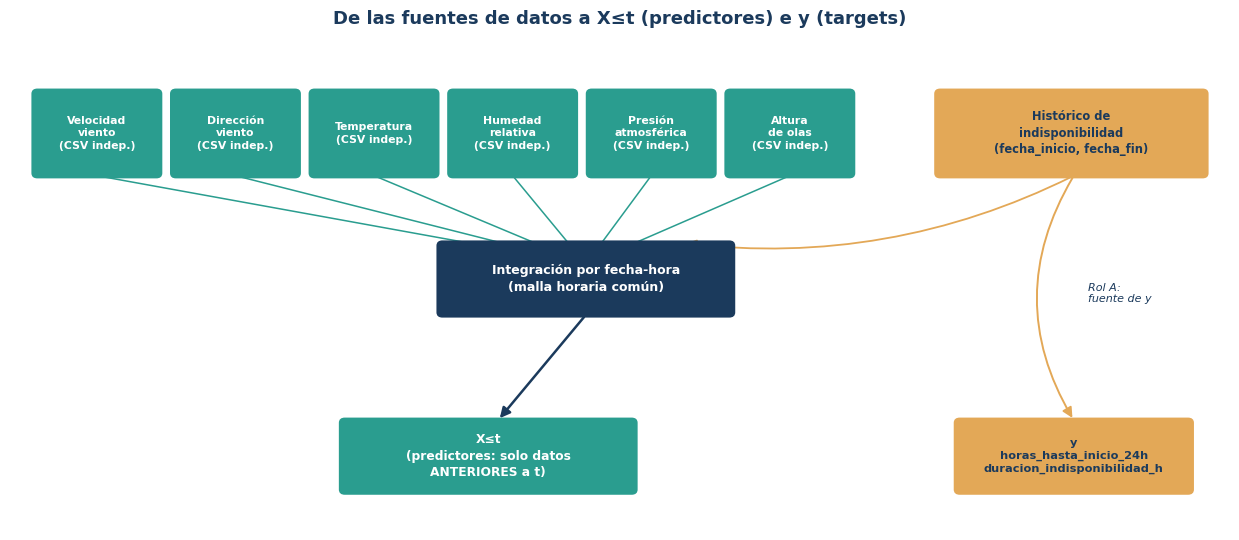

In [ ]:
variables = ['Velocidad\nviento', 'Dirección\nviento', 'Temperatura', 'Humedad\nrelativa', 'Presión\natmosférica', 'Altura\nde olas']

fig, ax = lienzo(12.5, 5.5, xlim=(0, 12.5), ylim=(0, 5.8))
ax.set_title('De las fuentes de datos a X\u2264t (predictores) e y (targets)', fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=12)

x0 = 0.25
w, gap = 1.28, 0.14
for i, v in enumerate(variables):
    x = x0 + i * (w + gap)
    caja(ax, x, 4.2, w, 1.0, v + '\n(CSV indep.)', color=COLOR_TEAL, fontsize=7.8)
    flecha(ax, (x + w/2, 4.2), (5.9, 3.15), color=COLOR_TEAL, lw=1.1)

caja(ax, 9.5, 4.2, 2.75, 1.0, 'Histórico de\nindisponibilidad\n(fecha_inicio, fecha_fin)', color=COLOR_GOLD, texto_color=COLOR_NAVY, fontsize=8.3)

caja(ax, 4.4, 2.55, 3.0, 0.85, 'Integración por fecha-hora\n(malla horaria común)', color=COLOR_NAVY, fontsize=9)
flecha(ax, (10.9, 4.2), (6.9, 3.4), color=COLOR_GOLD, lw=1.3, rad=-0.15)
flecha(ax, (10.9, 4.2), (10.9, 1.3), color=COLOR_GOLD, lw=1.4, rad=0.3)
ax.text(11.05, 2.7, 'Rol A:\nfuente de y', fontsize=8, color=COLOR_NAVY, style='italic')

flecha(ax, (5.9, 2.55), (5.0, 1.3))
caja(ax, 3.4, 0.45, 3.0, 0.85, 'X\u2264t\n(predictores: solo datos\nANTERIORES a t)', color=COLOR_TEAL, fontsize=8.8)

caja(ax, 9.7, 0.45, 2.4, 0.85, 'y\nhoras_hasta_inicio_24h\nduracion_indisponibilidad_h', color=COLOR_GOLD, texto_color=COLOR_NAVY, fontsize=8.2)

plt.tight_layout()
plt.show()


##### 2.1.2.1.1 Dos roles distintos del histórico de indisponibilidad

Es importante distinguir, desde ya, **dos usos del mismo histórico de eventos**, porque ambos alimentan al Machine Learning pero de forma distinta:

**Rol A — Fuente de las etiquetas `y`.** `fecha_inicio` y `fecha_fin` de cada evento generan `horas_hasta_inicio_24h` y `duracion_indisponibilidad_h` (sección 2.1.2.3). Esto es lo que el modelo aprende a predecir.

**Rol B — Caracterización del evento (evidencia causal, no predictor).** Mientras el terminal está indisponible (por ejemplo, del 17/09/2026 20:25 al 17/09/2026 21:25), el sensor meteo-oceanográficos **siguen registrando en simultáneo**. Esas lecturas dicen qué condiciones acompañaron o causaron esa indisponibilidad específica, y sirven para: (i) confirmar que el evento tiene causa meteo-oceanográfica y no otra (control **Q04**, decisión **D02**); (ii) el análisis exploratorio que justifica qué variable(s) y qué umbrales típicamente preceden un evento(https://prnt.sc/mqogd2sxwABj).

> **Regla que no debe romperse (Q07 — anti data-leakage):** las lecturas registradas *durante* el evento (20:25–21:25 en el ejemplo) **entrenan indirectamente** al modelo — porque ayudan a etiquetar y entender el fenómeno — pero **nunca entran como columnas de `X_≤t`** para predecir ese mismo evento. El modelo, en producción, se ejecuta en un instante `t` anterior al inicio (ej. a las 19:00) y en ese momento las lecturas de las 20:25–21:25 todavía no existen. `X_≤t` se construye exclusivamente con la ventana de lookback **anterior** a `fecha_inicio`, nunca con la ventana interior al evento.


**Vista visual — qué puede y qué no puede usarse como predictor (Q07):**

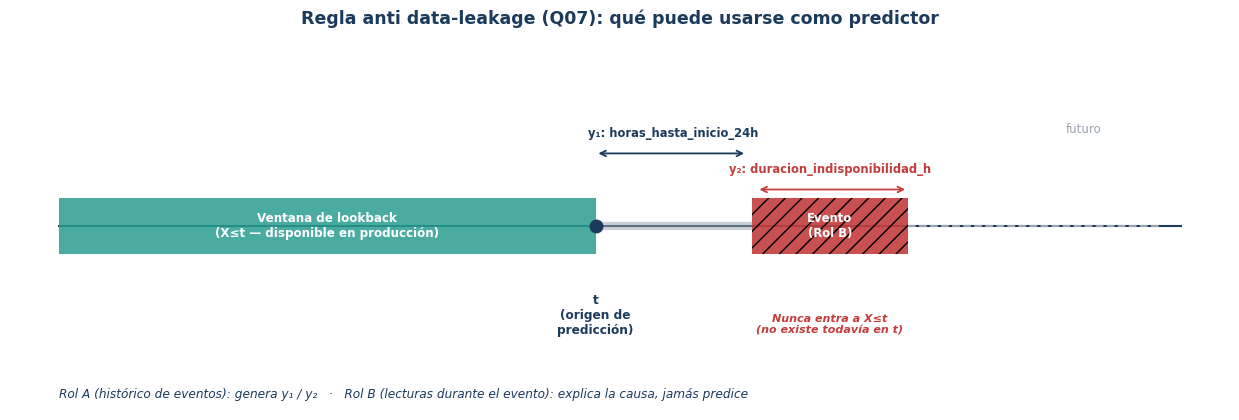

In [ ]:
fig, ax = lienzo(12.5, 4.3, xlim=(0, 12.5), ylim=(0, 4.6))
ax.set_title('Regla anti data-leakage (Q07): qué puede usarse como predictor', fontsize=12.5, color=COLOR_NAVY, fontweight='bold', pad=12)

y_line = 2.3
ax.plot([0.5, 12.0], [y_line, y_line], color=COLOR_NAVY, lw=1.5, zorder=1)

rect1 = Rectangle((0.5, y_line - 0.35), 5.5, 0.7, facecolor=COLOR_TEAL, alpha=0.85, zorder=2)
ax.add_patch(rect1)
ax.text(3.25, y_line, 'Ventana de lookback\n(X\u2264t — disponible en producción)', ha='center', va='center', fontsize=8.6, color='white', fontweight='bold')

ax.plot([6.0], [y_line], marker='o', color=COLOR_NAVY, markersize=9, zorder=3)
ax.text(6.0, y_line - 1.35, 't\n(origen de\npredicción)', ha='center', fontsize=8.7, color=COLOR_NAVY, fontweight='bold')

ax.plot([6.0, 7.6], [y_line, y_line], color=COLOR_GRAY, lw=6, alpha=0.5, zorder=1, solid_capstyle='butt')

rect2 = Rectangle((7.6, y_line - 0.35), 1.6, 0.7, facecolor=COLOR_RED, alpha=0.9, hatch='//', zorder=2)
ax.add_patch(rect2)
ax.text(8.4, y_line, 'Evento\n(Rol B)', ha='center', va='center', fontsize=8.4, color='white', fontweight='bold')
ax.text(8.4, y_line - 1.35, 'Nunca entra a X\u2264t\n(no existe todavía en t)', ha='center', fontsize=8, color=COLOR_RED, style='italic', fontweight='bold')

ax.plot([9.2, 11.8], [y_line, y_line], color=COLOR_GRAY, lw=1.5, ls='--', zorder=1)
ax.text(11.0, y_line + 1.15, 'futuro', ha='center', fontsize=8.5, color=COLOR_GRAY)

ax.annotate('', xy=(7.55, y_line + 0.9), xytext=(6.0, y_line + 0.9),
            arrowprops=dict(arrowstyle='<->', color=COLOR_NAVY, lw=1.3))
ax.text(6.8, y_line + 1.1, 'y\u2081: horas_hasta_inicio_24h', ha='center', fontsize=8.3, color=COLOR_NAVY, fontweight='bold')

ax.annotate('', xy=(9.2, y_line + 0.45), xytext=(7.65, y_line + 0.45),
            arrowprops=dict(arrowstyle='<->', color=COLOR_RED, lw=1.3))
ax.text(8.4, y_line + 0.65, 'y\u2082: duracion_indisponibilidad_h', ha='center', fontsize=8.3, color=COLOR_RED, fontweight='bold')

ax.text(0.5, 0.15, 'Rol A (histórico de eventos): genera y\u2081 / y\u2082   ·   Rol B (lecturas durante el evento): explica la causa, jamás predice',
        fontsize=8.7, color=COLOR_NAVY, ha='left', style='italic')

plt.tight_layout()
plt.show()


> **Nota de integración (bisagra hacia HU03/HU04):** cada variable meteo-oceanográfica llega en un archivo separado con su propia frecuencia de muestreo. Para construir $X_{\le t}$ es necesario remuestrear/alinear todas las variables a una malla horaria común **antes** de calcular ventanas de lookback. El histórico de indisponibilidad, en cambio, no se remuestrea: se usa tal cual (evento a evento) para construir las etiquetas, como se detalla a continuación.

#### 2.1.2.2 Definición técnica de las dos variables objetivo

Se definen dos variables objetivo, ambas **continuas, no negativas y expresadas en horas**, referidas al **próximo evento de indisponibilidad cuyo inicio cae dentro de la ventana futura de 24 horas** desde cada origen de predicción `t`:

##### Variable objetivo 1 — Horas hasta el inicio

```text
horas_hasta_inicio_24h
```

Tiempo, en horas, entre el instante de predicción `t` y el inicio del próximo evento de indisponibilidad, **condicionado a que ese inicio ocurra dentro de `(t, t+24h]`**.

##### Variable objetivo 2 — Duración del evento

```text
duracion_indisponibilidad_h
```

Duración, en horas, del evento cuyo inicio predice la variable anterior. Se calcula como `fecha_fin − fecha_inicio` de ese mismo evento en el histórico.

##### Variable derivada (no se modela directamente)

```text
hora_fin_predicha = t + horas_hasta_inicio_24h + duracion_indisponibilidad_h
```

El fin **no es una tercera variable objetivo**: es aritmética directa sobre las dos anteriores. Modelarlo por separado sería redundante y podría generar inconsistencias (que el fin predicho no coincida con inicio + duración predichos).

##### Especificación temporal (ambas variables)

- **Granularidad base del pipeline:** 1 hora.
- **Origen de predicción:** `t`.
- **Horizonte:** 24 horas.
- **Regla de horizonte:** el horizonte de 24 h significa que el **inicio** del evento debe ocurrir *dentro* de `(t, t+24h]`, no que el evento comience recién después de que transcurran las 24 h.
- **Unidad de salida:** horas, en ambos casos.
- **Tarea de ML:** regresión supervisada de dos salidas (dos regresores o un regresor multisalida), sobre el mismo conjunto de predictores $X_{\le t}$.


In [ ]:
target_spec_dual = pd.DataFrame([
    ['horas_hasta_inicio_24h', 'Horas desde t hasta el inicio del próximo evento', 'Cuantitativa continua', 'No negativa', 'Horas', '(t, t+24h]', 'fecha_inicio del evento más próximo cuyo inicio cae en la ventana'],
    ['duracion_indisponibilidad_h', 'Duración del evento cuyo inicio se predijo', 'Cuantitativa continua', 'No negativa', 'Horas', 'Depende del evento seleccionado por la 1ra variable', 'fecha_fin - fecha_inicio de ese mismo evento'],
], columns=['Nombre técnico', 'Definición', 'Tipo estadístico', 'Signo', 'Unidad', 'Ventana de referencia', 'Cómo se calcula desde el histórico'])

display(target_spec_dual)

target_meta = pd.DataFrame([
    ['Unidad temporal base', '1 hora'],
    ['Horizonte de predicción', '24 horas hacia adelante'],
    ['Regla de horizonte', 'El INICIO del evento debe caer dentro de (t, t+24h]; el evento puede extenderse más allá si la duración lo excede'],
    ['Fuente primaria', 'Histórico de indisponibilidad operativa: fecha_inicio y fecha_fin por evento'],
    ['Relación con features', 'Los predictores (variables meteo-oceanográficas) solo pueden estar disponibles hasta t'],
    ['Alcance del modelo', 'Predice el evento MÁS PRÓXIMO dentro del horizonte, no la lista completa de eventos si hubiera más de uno'],
    ['Riesgo metodológico clave', 'Data leakage si se incorporan datos posteriores a t como entrada'],
    ['Familia de algoritmos planificada', 'GBM: XGBoost / LightGBM (y Random Forest / regresión lineal como líneas base de comparación)'],
], columns=['Propiedad', 'Definición'])

display(target_meta)


,Nombre técnico,Definición,Tipo estadístico,Signo,Unidad,Ventana de referencia,Cómo se calcula desde el histórico
0,horas_hasta_inicio_24h,Horas desde t hasta el inicio del próximo evento,Cuantitativa continua,No negativa,Horas,"(t, t+24h]",fecha_inicio del evento más próximo cuyo inicio cae en la ventana
1,duracion_indisponibilidad_h,Duración del evento cuyo inicio se predijo,Cuantitativa continua,No negativa,Horas,Depende del evento seleccionado por la 1ra variable,fecha_fin - fecha_inicio de ese mismo evento


,Propiedad,Definición
0,Unidad temporal base,1 hora
1,Horizonte de predicción,24 horas hacia adelante
2,Regla de horizonte,"El INICIO del evento debe caer dentro de (t, t+24h]; el evento puede extenderse más allá si la duración lo excede"
3,Fuente primaria,Histórico de indisponibilidad operativa: fecha_inicio y fecha_fin por evento
4,Relación con features,Los predictores (variables meteo-oceanográficas) solo pueden estar disponibles hasta t
5,Alcance del modelo,"Predice el evento MÁS PRÓXIMO dentro del horizonte, no la lista completa de eventos si hubiera más de uno"
6,Riesgo metodológico clave,Data leakage si se incorporan datos posteriores a t como entrada
7,Familia de algoritmos planificada,GBM: XGBoost / LightGBM (y Random Forest / regresión lineal como líneas base de comparación)


#### 2.1.2.3 Definición matemática de las dos etiquetas

Sea `t` el instante de origen de la predicción y `H = 24 h` el horizonte. Sea cada evento histórico de indisponibilidad un intervalo:

\[
I_j = [s_j, e_j)
\]

con `s_j` como fecha-hora de inicio y `e_j` como fecha-hora de finalización (ambas provienen directamente del histórico de eventos).

**Paso 1 — Selección del evento relevante para el origen `t`.** Se identifica el evento cuyo inicio es el más próximo hacia adelante y cae dentro del horizonte:

\[
j^{*}(t) = \arg\min_{j} \; \{\, s_j - t \;:\; s_j > t,\; s_j - t \le H \,\}
\]

**Paso 2 — Etiquetas, si existe `j*(t)`:**

\[
y^{inicio}_t = s_{j^{*}(t)} - t \qquad \text{(horas)}
\]

\[
y^{duracion}_t = e_{j^{*}(t)} - s_{j^{*}(t)} \qquad \text{(horas)}
\]

**Paso 3 — Si no existe ningún evento cuyo inicio caiga en `(t, t+H]`:** el origen `t` no tiene un par `(y_inicio, y_duracion)` válido dentro del horizonte. Este caso **no se fuerza a cero**; se marca aparte (ver regla de calidad Q10 más abajo), porque cero horas hasta el inicio significaría "el evento empieza ahora mismo", que es semánticamente distinto de "no hay evento".

**Fin derivado (no es una etiqueta de entrenamiento independiente):**

\[
\widehat{fin}(t) = t + \hat{y}^{inicio}_t + \hat{y}^{duracion}_t
\]

> **Control de dominio a validar:** si el evento seleccionado inicia dentro de la ventana, se espera `0 < y_inicio ≤ 24`. `y_duracion` no tiene ese mismo techo: el evento puede iniciar dentro del horizonte y extenderse más allá de las 24 h — eso es válido y debe documentarse como comportamiento esperado, no como error.


**Vista visual — Paso 1: línea de tiempo y selección del evento relevante j\*(t):**

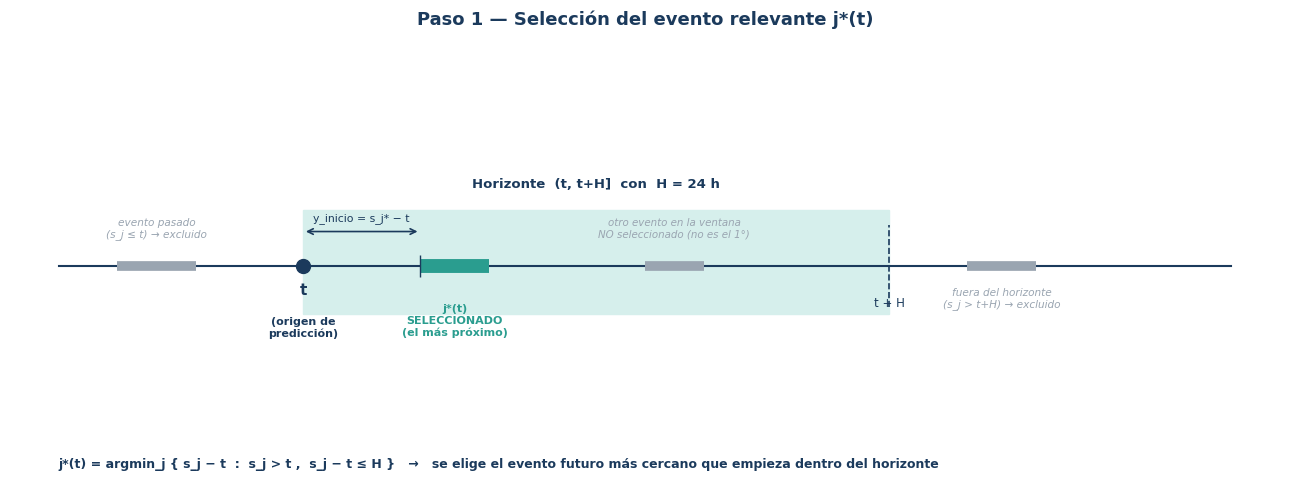

In [ ]:
fig, ax = lienzo(13, 5.0, xlim=(0, 13), ylim=(0, 5.3))
ax.set_title('Paso 1 — Selección del evento relevante j*(t)', fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=14)

y_line = 2.6
ax.plot([0.5, 12.5], [y_line, y_line], color=COLOR_NAVY, lw=1.5, zorder=1)

# t (origen de predicción)
t_x = 3.0
ax.plot([t_x], [y_line], marker='o', color=COLOR_NAVY, markersize=10, zorder=4)
ax.text(t_x, y_line-0.35, 't', ha='center', fontsize=11, color=COLOR_NAVY, fontweight='bold')
ax.text(t_x, y_line-0.62, '(origen de\npredicción)', ha='center', va='top', fontsize=8, color=COLOR_NAVY, fontweight='bold')

# horizonte sombreado (t, t+H]
h_end = t_x + 6.0
ax.axvspan(t_x, h_end, ymin=0.38, ymax=0.62, color=COLOR_TEAL_LT, zorder=0)
ax.plot([h_end, h_end], [y_line-0.5, y_line+0.5], color=COLOR_NAVY, lw=1.2, ls='--')
ax.text((t_x+h_end)/2, y_line+0.95, 'Horizonte  (t, t+H]  con  H = 24 h', ha='center', fontsize=9.5,
        color=COLOR_NAVY, fontweight='bold')
ax.text(h_end, y_line-0.5, 't + H', ha='center', fontsize=8.5, color=COLOR_NAVY)

# evento pasado (excluido: s_j <= t)
ax.plot([1.1, 1.9], [y_line, y_line], color=COLOR_GRAY, lw=7, solid_capstyle='butt', zorder=2)
ax.text(1.5, y_line+0.35, 'evento pasado\n(s_j ≤ t) → excluido', ha='center', fontsize=7.6, color=COLOR_GRAY, style='italic')

# evento seleccionado j*(t): el más cercano dentro del horizonte
s1, e1 = t_x+1.2, t_x+1.9
ax.plot([s1, e1], [y_line, y_line], color=COLOR_TEAL, lw=10, solid_capstyle='butt', zorder=3)
ax.plot([s1], [y_line], marker='|', color=COLOR_NAVY, markersize=16, zorder=4)
ax.text((s1+e1)/2, y_line-0.85, 'j*(t)\nSELECCIONADO\n(el más próximo)', ha='center', fontsize=8, color=COLOR_TEAL, fontweight='bold')
ax.annotate('', xy=(s1, y_line+0.42), xytext=(t_x, y_line+0.42), arrowprops=dict(arrowstyle='<->', color=COLOR_NAVY, lw=1.2))
ax.text((t_x+s1)/2, y_line+0.55, 'y_inicio = s_j* − t', ha='center', fontsize=7.8, color=COLOR_NAVY)

# segundo evento dentro del horizonte pero NO seleccionado
s2, e2 = t_x+3.5, t_x+4.1
ax.plot([s2, e2], [y_line, y_line], color=COLOR_GRAY, lw=7, solid_capstyle='butt', zorder=2)
ax.text((s2+e2)/2, y_line+0.35, 'otro evento en la ventana\nNO seleccionado (no es el 1°)', ha='center', fontsize=7.4, color=COLOR_GRAY, style='italic')

# evento fuera del horizonte (excluido: s_j > t+H)
s3, e3 = h_end+0.8, h_end+1.5
ax.plot([s3, e3], [y_line, y_line], color=COLOR_GRAY, lw=7, solid_capstyle='butt', zorder=2)
ax.text((s3+e3)/2, y_line-0.5, 'fuera del horizonte\n(s_j > t+H) → excluido', ha='center', fontsize=7.6, color=COLOR_GRAY, style='italic')

ax.text(0.5, 0.15,
        'j*(t) = argmin_j { s_j − t  :  s_j > t ,  s_j − t ≤ H }   →   se elige el evento futuro más cercano que empieza dentro del horizonte',
        fontsize=9, color=COLOR_NAVY, ha='left', fontweight='bold')

plt.tight_layout()
plt.show()

**Vista visual — Pasos 2 y 3: fórmulas de las etiquetas, caso sin evento y control de dominio:**

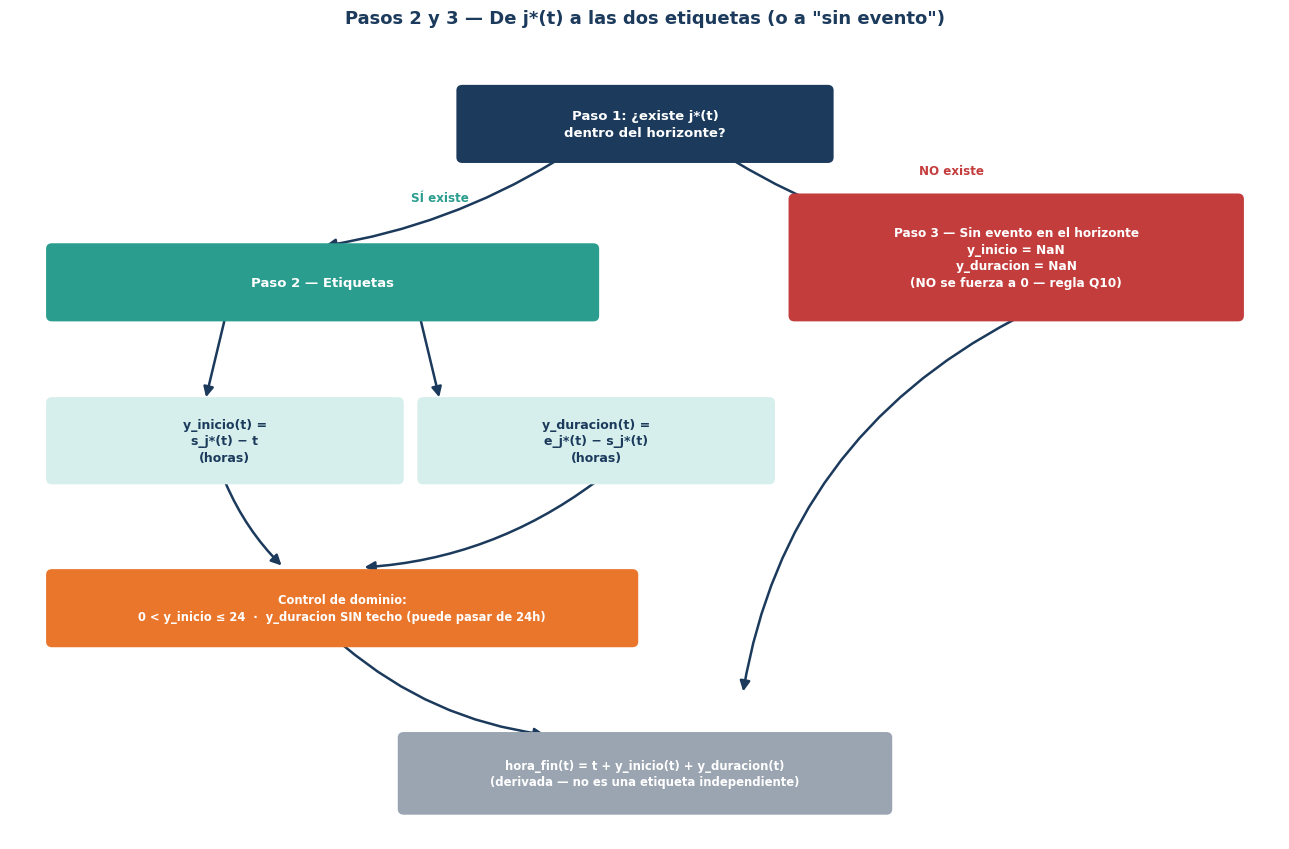

In [ ]:
fig, ax = lienzo(13, 8.6, xlim=(0, 13), ylim=(0, 8.8))
ax.set_title('Pasos 2 y 3 — De j*(t) a las dos etiquetas (o a "sin evento")', fontsize=13,
             color=COLOR_NAVY, fontweight='bold', pad=14)

caja(ax, 4.6, 7.5, 3.8, 0.8, 'Paso 1: ¿existe j*(t)\ndentro del horizonte?', color=COLOR_NAVY, fontsize=9.5)

flecha(ax, (5.6, 7.5), (3.2, 6.55), rad=-0.1)
ax.text(4.1, 7.05, 'SÍ existe', fontsize=8.6, color=COLOR_TEAL, fontweight='bold')
flecha(ax, (7.4, 7.5), (9.8, 6.55), rad=0.1)
ax.text(9.3, 7.35, 'NO existe', fontsize=8.6, color=COLOR_RED, fontweight='bold')

# rama SÍ: Paso 2, dos fórmulas
caja(ax, 0.4, 5.75, 5.6, 0.8, 'Paso 2 — Etiquetas', color=COLOR_TEAL, fontsize=9.5)
flecha(ax, (2.2, 5.75), (2.0, 4.85))
flecha(ax, (4.2, 5.75), (4.4, 4.85))

caja(ax, 0.4, 3.95, 3.6, 0.9, 'y_inicio(t) =\ns_j*(t) − t\n(horas)', color=COLOR_TEAL_LT, texto_color=COLOR_NAVY, fontsize=9)
caja(ax, 4.2, 3.95, 3.6, 0.9, 'y_duracion(t) =\ne_j*(t) − s_j*(t)\n(horas)', color=COLOR_TEAL_LT, texto_color=COLOR_NAVY, fontsize=9)

flecha(ax, (2.2, 3.95), (2.8, 3.0), rad=0.1)
flecha(ax, (6.0, 3.95), (3.6, 3.0), rad=-0.15)

# control de dominio
caja(ax, 0.4, 2.15, 6.0, 0.8, 'Control de dominio:\n0 < y_inicio ≤ 24  ·  y_duracion SIN techo (puede pasar de 24h)', color=COLOR_ORANGE, fontsize=8.3)

# rama NO: Paso 3
caja(ax, 8.0, 5.75, 4.6, 1.35, 'Paso 3 — Sin evento en el horizonte\ny_inicio = NaN\ny_duracion = NaN\n(NO se fuerza a 0 — regla Q10)', color=COLOR_RED, fontsize=8.7)

# hora_fin derivada (combina ambas ramas)
flecha(ax, (3.4, 2.15), (5.5, 1.15), rad=0.15)
flecha(ax, (10.3, 5.75), (7.5, 1.6), rad=0.25)
caja(ax, 4.0, 0.3, 5.0, 0.85, 'hora_fin(t) = t + y_inicio(t) + y_duracion(t)\n(derivada — no es una etiqueta independiente)', color=COLOR_GRAY, fontsize=8.4)

plt.tight_layout()
plt.show()

#### 2.1.2.4 Reglas de negocio y calidad necesarias para construir ambos targets

La formalización anterior solo es correcta si la semántica de los registros está controlada. Antes de generar las etiquetas reales deben resolverse las siguientes reglas:

1. **Cero no equivale a dato faltante.** Ausencia de un registro de indisponibilidad no debe interpretarse automáticamente como "no habrá evento"; puede ser ausencia de captura.
2. **Inicio y fin deben ser temporalmente válidos.** Un evento con `fin < inicio` es inconsistente y debe revisarse antes de derivar la duración.
3. **La causa del evento debe estar clara.** La investigación busca explicar indisponibilidad mediante condiciones meteorológicas y oceanográficas; no debe mezclarse con indisponibilidad por mantenimiento, fallas eléctricas u otras causas no climáticas.
4. **La zona horaria debe ser uniforme.** Todos los sensores (archivos CSV de variables) y el registro de eventos deben quedar en la misma referencia temporal antes de alinearse.
5. **Un solo evento por origen `t`.** El modelo, tal como se define aquí, predice el evento **más próximo** dentro del horizonte. Si existiera más de un evento en la misma ventana de 24 h, los eventos posteriores al primero **no** se incluyen en `y_inicio`/`y_duracion` de ese origen — esto mencionamos como alcance/limitación del modelo, no resolverse implícitamente.
6. **Ausencia de evento dentro del horizonte.** Los orígenes `t` sin evento válido en `(t, t+24h]` deben tratarse explícitamente (excluirlos del entrenamiento de los regresores, o usarlos como clase negativa de un clasificador previo de ocurrencia) — nunca imputarse como `y_inicio = 0` o `y_duracion = 0`.
7. **La última parte de la serie necesita tratamiento especial.** Para evaluar si existe evento dentro de las 24 h posteriores a `t`, se requiere conocer esas 24 h; las últimas observaciones del histórico pueden no tener ventana futura completa.
8. **Las etiquetas futuras nunca pueden usarse como predictor.** `fecha_inicio` y `fecha_fin` del evento pertenecen a `y`, no a `X`.
9. **Las lecturas registradas DURANTE el evento tampoco son predictor de ese mismo evento.** Los valores que marcan los sensores mientras dura la indisponibilidad (Rol B, sección 2.1.2.1.1) sirven para caracterizar y validar la causa del evento, no para construir `X_≤t` — en el instante `t` de predicción esas lecturas todavía no existen.


In [ ]:
reglas_calidad_target = pd.DataFrame([
    ['Q01', 'Timestamps parseables', 'fecha_inicio y fecha_fin se convierten a datetime sin error', 'Obligatorio'],
    ['Q02', 'Orden temporal', 'fecha_fin > fecha_inicio en cada evento', 'Obligatorio'],
    ['Q03', 'Duplicados', 'eventos duplicados identificados y tratados', 'Obligatorio'],
    ['Q04', 'Causa de indisponibilidad', 'criterio de inclusión/exclusión (solo meteo-oceanográfica) documentado', 'Obligatorio'],
    ['Q05', 'Zona horaria', 'sensores (CSV de variables) y eventos usan referencia temporal compatible', 'Obligatorio'],
    ['Q06', 'Cobertura futura', 'cada origen t tiene 24 h posteriores observables para evaluar ocurrencia', 'Obligatorio'],
    ['Q07', 'No fuga de información', 'ningún predictor contiene datos posteriores a t', 'Obligatorio'],
    ['Q08', 'Evento más próximo bien seleccionado', 'j*(t) corresponde al menor s_j - t entre los que cumplen 0 < s_j - t <= 24', 'Obligatorio'],
    ['Q09', 'Eventos múltiples en la ventana', 'regla documentada: solo se etiqueta el primero; los siguientes no generan fila adicional para ese t', 'Obligatorio'],
    ['Q10', 'Ausencia de evento en el horizonte', 'orígenes t sin evento se excluyen o se marcan (no se fuerza y_inicio=0 / y_duracion=0)', 'Obligatorio'],
    ['Q11', 'Separación Rol A / Rol B del histórico', 'columnas *_durante_evento (caracterización) nunca se copian dentro de X_<=t', 'Obligatorio'],
], columns=['ID', 'Control', 'Criterio', 'Estado en Sprint 1'])
display(reglas_calidad_target)


,ID,Control,Criterio,Estado en Sprint 1
0,Q01,Timestamps parseables,fecha_inicio y fecha_fin se convierten a datetime sin error,Obligatorio
1,Q02,Orden temporal,fecha_fin > fecha_inicio en cada evento,Obligatorio
2,Q03,Duplicados,eventos duplicados identificados y tratados,Obligatorio
3,Q04,Causa de indisponibilidad,criterio de inclusión/exclusión (solo meteo-oceanográfica) documentado,Obligatorio
4,Q05,Zona horaria,sensores (CSV de variables) y eventos usan referencia temporal compatible,Obligatorio
5,Q06,Cobertura futura,cada origen t tiene 24 h posteriores observables para evaluar ocurrencia,Obligatorio
6,Q07,No fuga de información,ningún predictor contiene datos posteriores a t,Obligatorio
7,Q08,Evento más próximo bien seleccionado,j*(t) corresponde al menor s_j - t entre los que cumplen 0 < s_j - t <= 24,Obligatorio
8,Q09,Eventos múltiples en la ventana,regla documentada: solo se etiqueta el primero; los siguientes no generan fila adicional para ese t,Obligatorio
9,Q10,Ausencia de evento en el horizonte,orígenes t sin evento se excluyen o se marcan (no se fuerza y_inicio=0 / y_duracion=0),Obligatorio


**Vista visual — checklist de calidad Q01–Q11:**

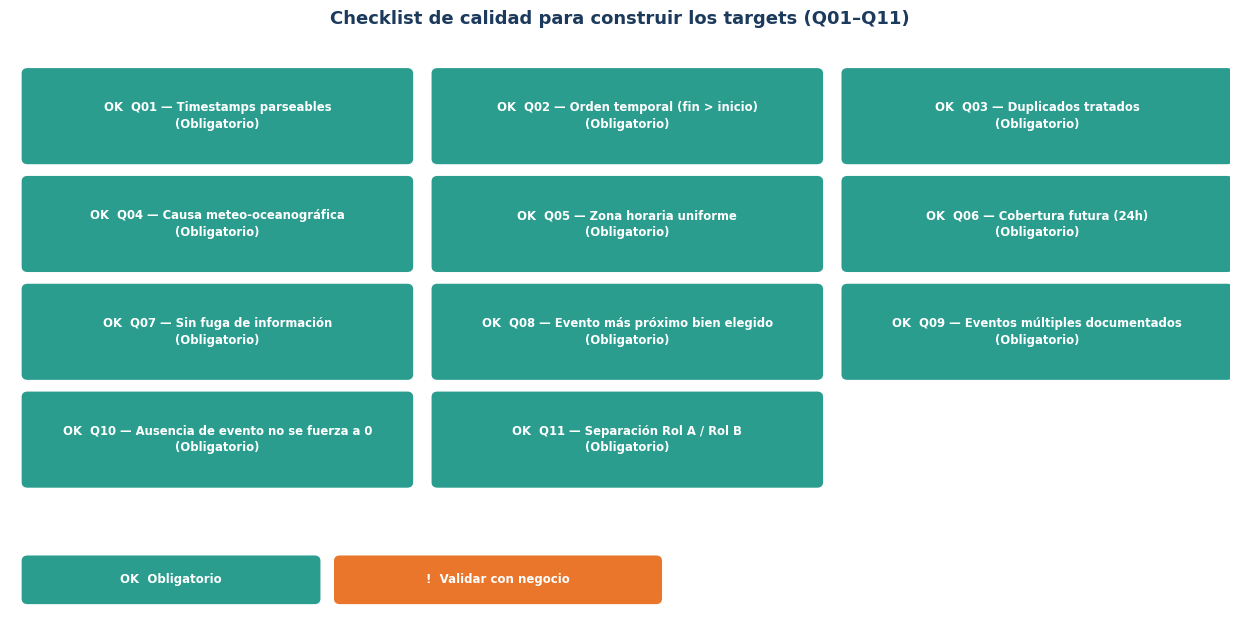

In [ ]:
reglas = [
    ('Q01', 'Timestamps parseables', 'Obligatorio'),
    ('Q02', 'Orden temporal (fin > inicio)', 'Obligatorio'),
    ('Q03', 'Duplicados tratados', 'Obligatorio'),
    ('Q04', 'Causa meteo-oceanográfica', 'Obligatorio'),
    ('Q05', 'Zona horaria uniforme', 'Obligatorio'),
    ('Q06', 'Cobertura futura (24h)', 'Obligatorio'),
    ('Q07', 'Sin fuga de información', 'Obligatorio'),
    ('Q08', 'Evento más próximo bien elegido', 'Obligatorio'),
    ('Q09', 'Eventos múltiples documentados', 'Obligatorio'),
    ('Q10', 'Ausencia de evento no se fuerza a 0', 'Obligatorio'),
    ('Q11', 'Separación Rol A / Rol B', 'Obligatorio'),
]

fig, ax = lienzo(12.5, 6.3, xlim=(0, 12.5), ylim=(0, 6.6))
ax.set_title('Checklist de calidad para construir los targets (Q01–Q11)', fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=12)

cols = 3
w, h = 3.95, 1.05
gapx, gapy = 0.25, 0.2
x0, y0 = 0.15, 5.2
for i, (qid, desc, estado) in enumerate(reglas):
    col = i % cols
    row = i // cols
    x = x0 + col * (w + gapx)
    y = y0 - row * (h + gapy)
    color = COLOR_TEAL if estado == 'Obligatorio' else COLOR_ORANGE
    icon = 'OK' if estado == 'Obligatorio' else '!'
    caja(ax, x, y, w, h, f'{icon}  {qid} — {desc}\n({estado})', color=color, fontsize=8.4)

caja(ax, 0.15, 0.1, 3.0, 0.5, 'OK  Obligatorio', color=COLOR_TEAL, fontsize=8.5)
caja(ax, 3.35, 0.1, 3.3, 0.5, '!  Validar con negocio', color=COLOR_ORANGE, fontsize=8.5)

plt.tight_layout()
plt.show()


#### 2.1.2.5 Distinción crítica: valores observados vs. valores predichos

Para evitar ambigüedades en nuestra tesis y en el código, se fija la siguiente nomenclatura:

| Momento | `horas_hasta_inicio_24h` | `duracion_indisponibilidad_h` |
|---|---|---|
| Observado (histórico, *ground truth*) | `horas_hasta_inicio_24h` | `duracion_indisponibilidad_h` |
| Predicho por el modelo | `horas_hasta_inicio_24h_pred` | `duracion_indisponibilidad_h_pred` |

El fin sigue la misma lógica: `hora_fin_observada` (derivada del histórico) vs. `hora_fin_predicha` (derivada de las dos predicciones). En ningún caso la predicción debe reemplazar el registro histórico que se utiliza como referencia.

#### 2.1.2.6 Arquitectura de modelado propuesta (familia GBM)

Se mantiene la familia de algoritmos ya considerada en el benchmarking del proyecto (Gradient Boosting), aplicada ahora a dos salidas sobre el mismo conjunto de predictores $X_{\le t}$. Esta sección es un **anticipo técnico para las HU de modelado (Sprint 2/3)**; en HU01 solo se deja definida la arquitectura, no se ajustan modelos finales.


In [128]:
modelado_propuesto = pd.DataFrame([
    ['Regresor A', 'horas_hasta_inicio_24h', 'Regresión', 'XGBoost Regressor (GBM) — LightGBM y Random Forest como comparación', 'MAE, RMSE (horas)'],
    ['Regresor B', 'duracion_indisponibilidad_h', 'Regresión', 'XGBoost Regressor (GBM) — LightGBM y Random Forest como comparación', 'MAE, RMSE (horas)'],
    [' Clasificador previo', 'ocurre_evento_24h (0/1)', 'Clasificación', 'XGBoost Classifier / Random Forest Classifier', 'F1, AUC'],
], columns=['Componente', 'Variable objetivo', 'Tipo de tarea', 'Algoritmo candidato (familia GBM)', 'Métrica principal'])

display(modelado_propuesto)


,Componente,Variable objetivo,Tipo de tarea,Algoritmo candidato (familia GBM),Métrica principal
0,Regresor A,horas_hasta_inicio_24h,Regresión,XGBoost Regressor (GBM) — LightGBM y Random Forest como comparación,"MAE, RMSE (horas)"
1,Regresor B,duracion_indisponibilidad_h,Regresión,XGBoost Regressor (GBM) — LightGBM y Random Forest como comparación,"MAE, RMSE (horas)"
2,Clasificador previo,ocurre_evento_24h (0/1),Clasificación,XGBoost Classifier / Random Forest Classifier,"F1, AUC"


**Vista visual — arquitectura de modelado propuesta:**

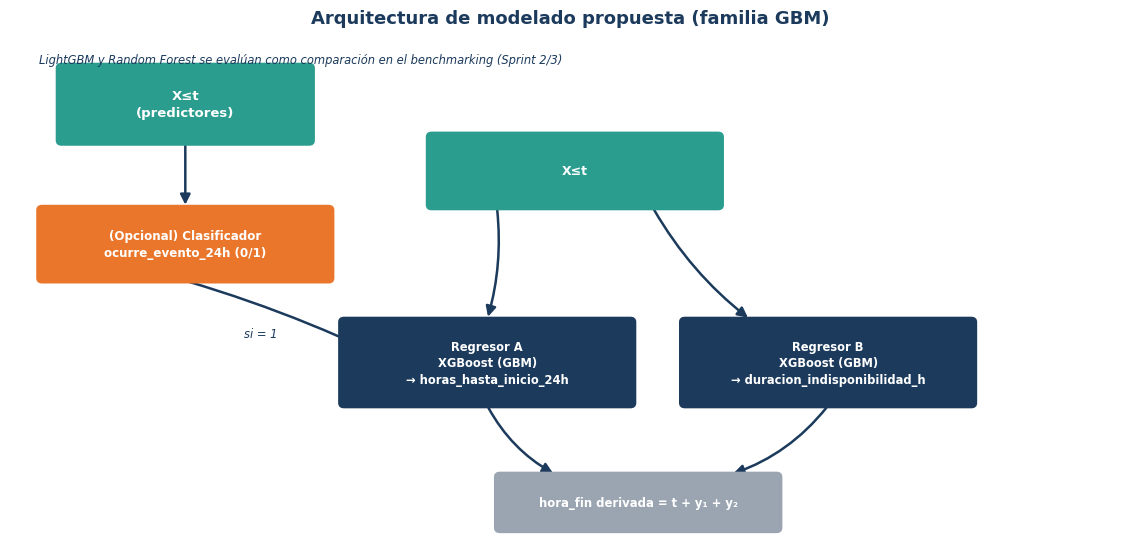

In [ ]:
fig, ax = lienzo(11.5, 5.6, xlim=(0, 11.5), ylim=(0, 5.8))
ax.set_title('Arquitectura de modelado propuesta (familia GBM)', fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=12)

caja(ax, 0.5, 4.6, 2.6, 0.9, 'X\u2264t\n(predictores)', color=COLOR_TEAL, fontsize=9.5)
flecha(ax, (1.8, 4.6), (1.8, 3.85))
caja(ax, 0.3, 3.0, 3.0, 0.85, '(Opcional) Clasificador\nocurre_evento_24h (0/1)', color=COLOR_ORANGE, fontsize=8.6)

flecha(ax, (1.8, 3.0), (4.3, 1.85), rad=-0.05)
ax.text(2.4, 2.35, 'si = 1', fontsize=8.3, color=COLOR_NAVY, style='italic')

caja(ax, 4.3, 3.85, 3.0, 0.85, 'X\u2264t', color=COLOR_TEAL, fontsize=9)
flecha(ax, (5.0, 3.85), (4.9, 2.55), rad=-0.1)
flecha(ax, (6.6, 3.85), (7.6, 2.55), rad=0.1)

caja(ax, 3.4, 1.55, 3.0, 1.0, 'Regresor A\nXGBoost (GBM)\n\u2192 horas_hasta_inicio_24h', color=COLOR_NAVY, fontsize=8.3)
caja(ax, 6.9, 1.55, 3.0, 1.0, 'Regresor B\nXGBoost (GBM)\n\u2192 duracion_indisponibilidad_h', color=COLOR_NAVY, fontsize=8.3)

flecha(ax, (4.9, 1.55), (5.6, 0.75), rad=0.15)
flecha(ax, (8.4, 1.55), (7.4, 0.75), rad=-0.15)
caja(ax, 5.0, 0.1, 2.9, 0.65, 'hora_fin derivada = t + y\u2081 + y\u2082', color=COLOR_GRAY, fontsize=8.4)

ax.text(0.3, 5.65, 'LightGBM y Random Forest se evalúan como comparación en el benchmarking (Sprint 2/3)',
        fontsize=8.3, color=COLOR_NAVY, style='italic', va='top')

plt.tight_layout()
plt.show()


> **Por qué sugerimos el clasificador previo, sin ser una tercera variable objetivo del alcance actual:** los dos regresores (inicio y duración) solo tienen sentido cuando existe un evento dentro del horizonte. Sin un filtro previo, el modelo se vería forzado a "inventar" un inicio y una duración incluso en ventanas de 24 h donde no ocurre ningún evento. Esta decisión queda registrada como **D07** en la tabla de decisiones abiertas (sección 2.1.2.8) para su validación con Operaciones

#### 2.1.2.7 Construcción reproducible de las dos etiquetas (código)

A continuación se implementa la función que construye `horas_hasta_inicio_24h` y `duracion_indisponibilidad_h` a partir de (a) una lista de orígenes de predicción `t` y (b) el histórico de eventos con `fecha_inicio`/`fecha_fin`. Es la misma lógica formalizada en la sección 2.1.2.3. Se ejecuta sobre los datos reales en la integración de HU03 (T06) y alimenta el análisis de HU04.


In [ ]:
def construir_targets_evento(timestamps, df_eventos, horizonte_h=24,
                              col_inicio='fecha_inicio', col_fin='fecha_fin'):
    # Construye las dos variables objetivo (horas_hasta_inicio_24h, duracion_indisponibilidad_h)
    # para cada instante de origen t en `timestamps`, usando el histórico de eventos `df_eventos`.
    #
    # Parámetros:
    #   timestamps   : Iterable[pd.Timestamp] - instantes de origen t
    #   df_eventos   : pd.DataFrame con columnas [col_inicio, col_fin] (datetime)
    #   horizonte_h  : tamaño del horizonte en horas (por defecto 24)
    #
    # Retorna: pd.DataFrame con columnas
    #   t, ocurre_evento_24h, horas_hasta_inicio_24h, duracion_indisponibilidad_h,
    #   evento_inicio, evento_fin
    eventos = df_eventos.copy()
    eventos[col_inicio] = pd.to_datetime(eventos[col_inicio])
    eventos[col_fin] = pd.to_datetime(eventos[col_fin])
    # Q02: descartar eventos temporalmente inválidos (fin <= inicio)
    eventos = eventos[eventos[col_fin] > eventos[col_inicio]].sort_values(col_inicio).reset_index(drop=True)

    inicios = eventos[col_inicio].values
    filas = []

    for t in pd.to_datetime(pd.Series(list(timestamps))):
        limite = t + pd.Timedelta(hours=horizonte_h)
        # Candidatos: inicio estrictamente posterior a t y dentro del horizonte (t, t+H]
        mask = (eventos[col_inicio] > t) & (eventos[col_inicio] <= limite)
        candidatos = eventos.loc[mask]

        if candidatos.empty:
            filas.append({
                't': t,
                'ocurre_evento_24h': 0,
                'horas_hasta_inicio_24h': np.nan,   # Q10: no se fuerza a 0
                'duracion_indisponibilidad_h': np.nan,
                'evento_inicio': pd.NaT,
                'evento_fin': pd.NaT,
            })
            continue

        # Q08: seleccionar el evento con el inicio más próximo a t
        evento_sel = candidatos.iloc[0]  # ya viene ordenado por fecha_inicio
        y_inicio = (evento_sel[col_inicio] - t) / pd.Timedelta(hours=1)
        y_duracion = (evento_sel[col_fin] - evento_sel[col_inicio]) / pd.Timedelta(hours=1)

        filas.append({
            't': t,
            'ocurre_evento_24h': 1,
            'horas_hasta_inicio_24h': round(y_inicio, 3),
            'duracion_indisponibilidad_h': round(y_duracion, 3),
            'evento_inicio': evento_sel[col_inicio],
            'evento_fin': evento_sel[col_fin],
        })

    return pd.DataFrame(filas)


#### 2.1.2.8 Riesgos de definición que deben cerrarse antes de la limpieza y el modelado

Estas preguntas no deben resolverse por suposición del equipo de Data Science. Requieren evidencia del dataset o validación con el responsable operativo:

- ¿La indisponibilidad histórica está registrada a nivel de los procesos operativos expuestos?  --Si
- ¿Todos los registros de indisponibilidad corresponden a causas meteo-oceanográficas?  --No
- ¿Un período sin registro significa **operación normal** o **ausencia de captura**?  --Ausencia de captura
- ¿Los timestamps de los archivos CSV de variables y del histórico de eventos usan la misma zona horaria y convención de fecha?  --Si
- ¿Pueden existir varios eventos dentro de una misma ventana de 24 h? --Si, pero tenemos un alcance que seria el más proximo.
- ¿La duración ya calculada en el sistema (si existe) coincide con `fecha_fin - fecha_inicio`? --Si
- ¿Qué hacer operativamente con los orígenes `t` que no tienen evento dentro del horizonte: excluirlos del entrenamiento de los regresores o entrenar primero un clasificador de ocurrencia? --Excluirlos

Responder estas preguntas forma parte de la calidad de la **comprensión de datos** y protege al proyecto contra etiquetas técnicamente calculables pero semánticamente incorrectas.


In [ ]:
decisiones_abiertas = pd.DataFrame([
    ['D01', 'Nivel de la indisponibilidad', 'Terminal vs. maniobra/activo', 'Operaciones / dueño del dato', 'Antes de construir el target final'],
    ['D02', 'Causa del evento', 'Solo meteo-oceanográfica vs. toda indisponibilidad', 'Operaciones / dueño del dato', 'Antes de filtrar históricos'],
    ['D03', 'Ausencia de registro', 'Cero real vs. dato faltante', 'Dueño del dato + Data/ML', 'Antes del EDA'],
    ['D04', 'Zona horaria', 'Referencia temporal oficial entre CSV de variables e histórico de eventos', 'Dueño de sensores / Data/ML', 'Antes de integrar fuentes'],
    ['D05', 'Horizonte operativo', 'Ratificar 24 h como horizonte principal', 'Operaciones / Product Owner', 'Durante Sprint 1'],
    ['D06', 'Eventos múltiples en el horizonte', 'Predecir solo el más próximo vs. modelar una lista/secuencia de eventos', 'Operaciones + Data/ML', 'Antes de HU05/HU06 (modelado)'],
    ['D07', 'Ausencia de evento en el horizonte', 'Excluir del entrenamiento vs. clasificador previo de ocurrencia (0/1)', 'Data/ML + Product Owner', 'Antes de HU05/HU06 (modelado)'],
], columns=['ID', 'Decisión', 'Alternativas a cerrar', 'Responsable sugerido', 'Momento'])
display(decisiones_abiertas)

,ID,Decisión,Alternativas a cerrar,Responsable sugerido,Momento
0,D01,Nivel de la indisponibilidad,Terminal vs. maniobra/activo,Operaciones / dueño del dato,Antes de construir el target final
1,D02,Causa del evento,Solo meteo-oceanográfica vs. toda indisponibilidad,Operaciones / dueño del dato,Antes de filtrar históricos
2,D03,Ausencia de registro,Cero real vs. dato faltante,Dueño del dato + Data/ML,Antes del EDA
3,D04,Zona horaria,Referencia temporal oficial entre CSV de variables e histórico de eventos,Dueño de sensores / Data/ML,Antes de integrar fuentes
4,D05,Horizonte operativo,Ratificar 24 h como horizonte principal,Operaciones / Product Owner,Durante Sprint 1
5,D06,Eventos múltiples en el horizonte,Predecir solo el más próximo vs. modelar una lista/secuencia de eventos,Operaciones + Data/ML,Antes de HU05/HU06 (modelado)
6,D07,Ausencia de evento en el horizonte,Excluir del entrenamiento vs. clasificador previo de ocurrencia (0/1),Data/ML + Product Owner,Antes de HU05/HU06 (modelado)


aass
**Vista visual — decisiones abiertas D01–D07:**

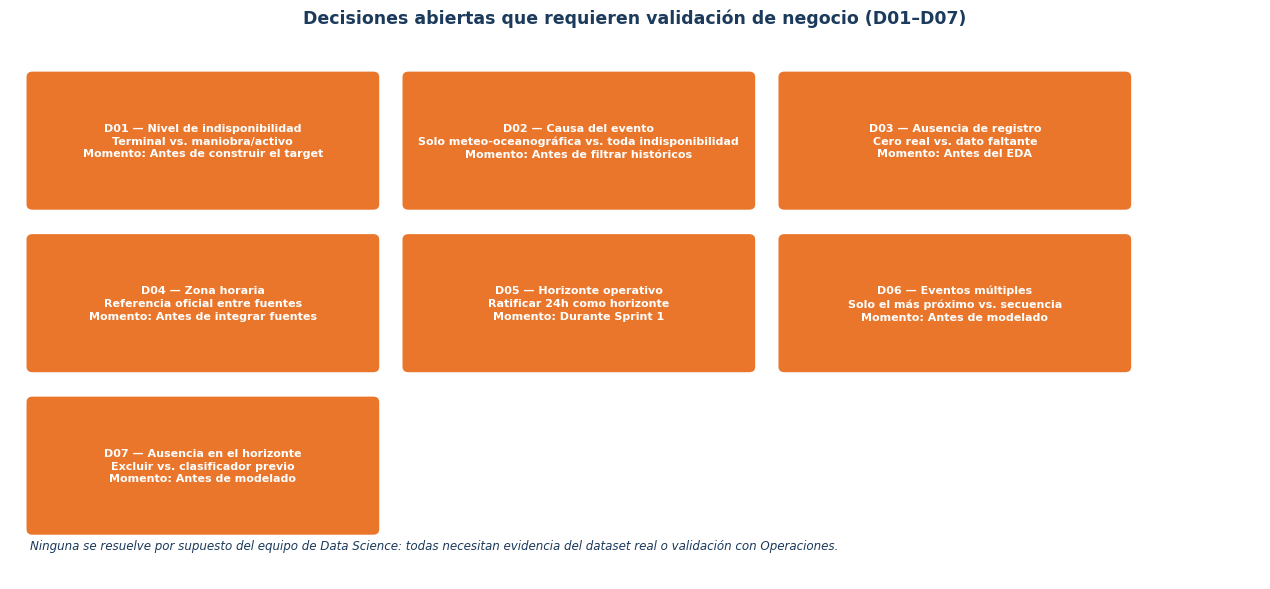

In [ ]:
decisiones_vis = [
    ('D01', 'Nivel de indisponibilidad', 'Terminal vs. maniobra/activo', 'Antes de construir el target'),
    ('D02', 'Causa del evento', 'Solo meteo-oceanográfica vs. toda indisponibilidad', 'Antes de filtrar históricos'),
    ('D03', 'Ausencia de registro', 'Cero real vs. dato faltante', 'Antes del EDA'),
    ('D04', 'Zona horaria', 'Referencia oficial entre fuentes', 'Antes de integrar fuentes'),
    ('D05', 'Horizonte operativo', 'Ratificar 24h como horizonte', 'Durante Sprint 1'),
    ('D06', 'Eventos múltiples', 'Solo el más próximo vs. secuencia', 'Antes de modelado'),
    ('D07', 'Ausencia en el horizonte', 'Excluir vs. clasificador previo', 'Antes de modelado'),
]

fig, ax = lienzo(12.8, 6.0, xlim=(0, 12.8), ylim=(0, 6.3))
ax.set_title('Decisiones abiertas que requieren validación de negocio (D01–D07)', fontsize=12.5, color=COLOR_NAVY, fontweight='bold', pad=12)

w, h = 3.55, 1.55
gapx, gapy = 0.3, 0.35
cols = 3
x0, y0 = 0.2, 4.35
for i, (did, tema, alt, momento) in enumerate(decisiones_vis):
    col = i % cols
    row = i // cols
    x = x0 + col * (w + gapx)
    y = y0 - row * (h + gapy)
    caja(ax, x, y, w, h, f'{did} — {tema}\n{alt}\nMomento: {momento}', color=COLOR_ORANGE, fontsize=8.0)

ax.text(0.2, 0.35, 'Ninguna se resuelve por supuesto del equipo de Data Science: todas necesitan evidencia del dataset real o validación con Operaciones.',
        fontsize=8.6, color=COLOR_NAVY, style='italic')

plt.tight_layout()
plt.show()


### Definition of Done — HU01 (T01 / T02)

La HU01 puede considerarse metodológicamente terminada cuando los siguientes artefactos queden revisados y versionados:

| Entregable | Tarea | Evidencia esperada | Estado inicial |
|---|---|---|---|
| Declaración del problema de negocio | T01 | Texto aprobado y alineado con el proceso *As-Is* | Definido en el documento base |
| Mapa problema → necesidad → salida predictiva | T01 | Matriz de trazabilidad | Incluido en este notebook |
| Pregunta predictiva formal (doble salida) | T01 | `X_(≤t) → (y_inicio, y_duracion)` | Incluido en este notebook |
| Ficha técnica de AMBAS variables objetivo | T02 | Nombre, unidad, tipo, horizonte, fuente y reglas para inicio y duración | Incluido en este notebook |
| Regla matemática de construcción de `y_inicio` y `y_duracion` | T02 | Fórmula reproducible + función `construir_targets_evento` | Incluido en este notebook (código) |
| Fuentes de datos identificadas (CSV por variable + histórico de eventos) | T02 | Tabla de fuentes con columnas clave y granularidad | Incluido en este notebook |
| Arquitectura de modelado (familia GBM) | T02 | Tabla de componentes (regresores + clasificador opcional) | Incluido en este notebook |
| Decisiones semánticas abiertas | T02 | Acta/validación con experto de negocio | Pendiente de validación |
| Controles mínimos de calidad | T02 | Checklist antes de generar las etiquetas finales | Incluido en este notebook |

> **Nota de gobernanza:** "incluido" no significa "aprobado por Operaciones". Las decisiones que cambian el significado del dato deben conservar evidencia de validación con el dueño del proceso o del dato.


In [129]:
dod = pd.DataFrame([
    ['T01', 'Problema de negocio formulado sin depender del algoritmo', 'CUMPLE - formulado'],
    ['T01', 'Proceso reactivo As-Is identificado', 'CUMPLE - documentado'],
    ['T01', 'Traducción a problema de regresión de doble salida', 'CUMPLE - formalizado'],
    ['T02', 'Dos variables objetivo continuas y en horas (inicio, duración)', 'CUMPLE - definidas'],
    ['T02', 'Unidad temporal horaria', 'CUMPLE - definida en documento base'],
    ['T02', 'Horizonte de 24 horas (evento dentro de la ventana)', 'CUMPLE - definido y formalizado'],
    ['T02', 'Fuentes de datos (CSV por variable + histórico de eventos)', 'CUMPLE - inventariadas'],
    ['T02', 'Función reproducible de construcción de targets', 'CUMPLE - implementada; se ejecuta sobre datos reales en HU03/T06'],
    ['T02', 'Arquitectura de modelado GBM (2 regresores + clasificador opcional)', 'CUMPLE - definida (el entrenamiento corresponde a la fase de Modelado)'],
    ['T02', 'Reglas de eventos múltiples y ausencia de evento', 'CUMPLE'],
    ['T02', 'Cero vs. faltante y zona horaria', 'CUMPLE - verificar con datos reales'],
], columns=['Tarea', 'Criterio', 'Estado'])
display(dod)


,Tarea,Criterio,Estado
0,T01,Problema de negocio formulado sin depender del algoritmo,CUMPLE - formulado
1,T01,Proceso reactivo As-Is identificado,CUMPLE - documentado
2,T01,Traducción a problema de regresión de doble salida,CUMPLE - formalizado
3,T02,"Dos variables objetivo continuas y en horas (inicio, duración)",CUMPLE - definidas
4,T02,Unidad temporal horaria,CUMPLE - definida en documento base
5,T02,Horizonte de 24 horas (evento dentro de la ventana),CUMPLE - definido y formalizado
6,T02,Fuentes de datos (CSV por variable + histórico de eventos),CUMPLE - inventariadas
7,T02,Función reproducible de construcción de targets,CUMPLE - implementada; se ejecuta sobre datos reales en HU03/T06
8,T02,Arquitectura de modelado GBM (2 regresores + clasificador opcional),CUMPLE - definida (el entrenamiento corresponde a la fase de Modelado)
9,T02,Reglas de eventos múltiples y ausencia de evento,CUMPLE


**Vista visual — tablero de cierre (Definition of Done):**

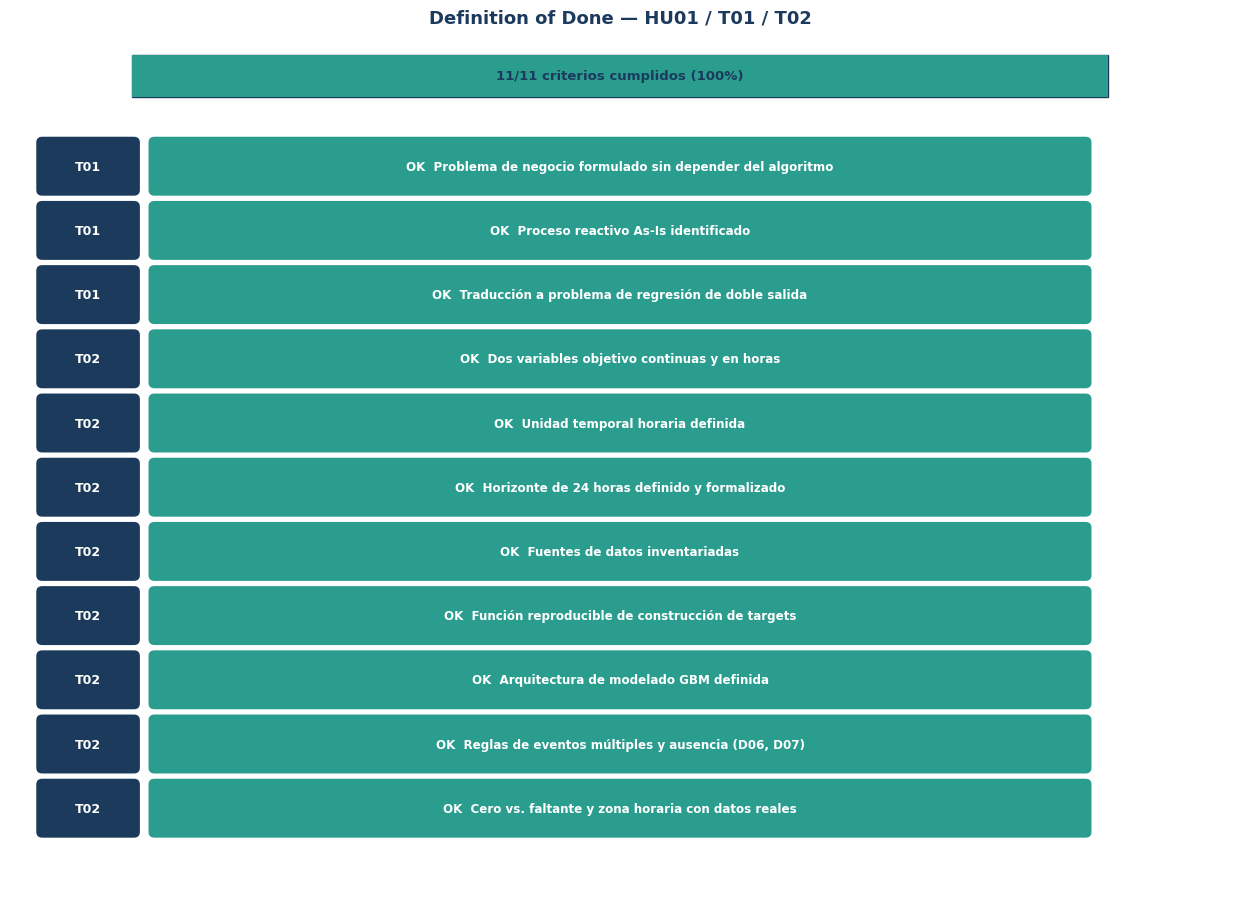

In [ ]:
items_dod = [
    ('T01', 'Problema de negocio formulado sin depender del algoritmo', 'ok'),
    ('T01', 'Proceso reactivo As-Is identificado', 'ok'),
    ('T01', 'Traducción a problema de regresión de doble salida', 'ok'),
    ('T02', 'Dos variables objetivo continuas y en horas', 'ok'),
    ('T02', 'Unidad temporal horaria definida', 'ok'),
    ('T02', 'Horizonte de 24 horas definido y formalizado', 'ok'),
    ('T02', 'Fuentes de datos inventariadas', 'ok'),
    ('T02', 'Función reproducible de construcción de targets', 'ok'),
    ('T02', 'Arquitectura de modelado GBM definida', 'ok'),
    ('T02', 'Reglas de eventos múltiples y ausencia (D06, D07)', 'ok'),
    ('T02', 'Cero vs. faltante y zona horaria con datos reales', 'ok'),
]
n_ok = sum(1 for _, _, e in items_dod if e == 'ok')
n_total = len(items_dod)

fig, ax = lienzo(12.5, 9.2, xlim=(0, 12.5), ylim=(0, 9.4))
ax.set_title('Definition of Done — HU01 / T01 / T02', fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=10)

bar_w = 10.0
ax.add_patch(Rectangle((1.25, 8.75), bar_w, 0.45, facecolor=COLOR_GRAY_LT, edgecolor=COLOR_NAVY, lw=1))
ax.add_patch(Rectangle((1.25, 8.75), bar_w * n_ok / n_total, 0.45, facecolor=COLOR_TEAL))
ax.text(1.25 + bar_w/2, 8.975, f'{n_ok}/{n_total} criterios cumplidos ({100*n_ok//n_total}%)', ha='center', va='center', fontsize=9.5, fontweight='bold', color=COLOR_NAVY)

y = 8.05
for tarea, texto, estado in items_dod:
    color = COLOR_TEAL if estado == 'ok' else COLOR_ORANGE
    icon = 'OK' if estado == 'ok' else 'PEND'
    caja(ax, 0.3, y - 0.35, 1.0, 0.58, tarea, color=COLOR_NAVY, fontsize=9)
    caja(ax, 1.45, y - 0.35, 9.6, 0.58, f'{icon}  {texto}', color=color, fontsize=8.6, texto_color='white')
    y -= 0.7

plt.tight_layout()
plt.show()


## 2.2 HU02 — Definición de métricas del modelo

**Sprint:** Sprint 1 — Comprensión del negocio y comprensión de datos  
**Historia de usuario:** HU02 — Definición de métricas del modelo  
**Tarea:** T03 — Definir métricas de evaluación: RMSE, MAPE, MAE y R²  

En esta HU se establecen las métricas que serán utilizadas para evaluar el desempeño de los modelos de regresión encargados de estimar las horas de indisponibilidad operativa. Se consideran **MAE, RMSE, MAPE y R²**.

> **Alcance T03:** esta sección define e implementa las métricas. La evaluación se realizará con las predicciones reales de los modelos GBM y la estrategia de validación temporal del proyecto (fase de Modelado); aquí no se entrena ni se evalúa ningún modelo.


### 2.2.1 T03 — Definir métricas de evaluación: RMSE, MAPE, MAE y R²

#### 2.2.1.1 Métricas seleccionadas

| Métrica | Nombre | Interpretación para el proyecto |
|---|---|---|
| **MAE** | Mean Absolute Error | Error absoluto medio de la predicción, expresado en horas. Permite interpretar directamente cuánto se desvía, en promedio, la predicción respecto al valor observado. |
| **RMSE** | Root Mean Square Error | Error cuadrático medio en su raíz, expresado en horas. Penaliza en mayor medida los errores de mayor magnitud. |
| **MAPE** | Mean Absolute Percentage Error | Error porcentual absoluto medio. Se calculará únicamente sobre observaciones cuyo valor real sea diferente de cero para evitar divisiones indefinidas. |
| **R²** | Coeficiente de determinación | Indica la proporción de la variabilidad de los valores observados explicada por las predicciones del modelo. |

**Criterio de interpretación general:** para MAE, RMSE y MAPE, valores menores representan menor error; para R², un valor más cercano a 1 indica mayor capacidad explicativa sobre los datos evaluados.

> **Nota:** estos criterios sirven para interpretar las métricas, pero no establecen por sí solos qué modelo será seleccionado. La comparación deberá considerar el conjunto de métricas y la validación temporal definida en las siguientes historias de usuario.


#### 2.2.1.2 Definición formal

Sea $y_i$ el valor observado, $\hat{y}_i$ el valor predicho y $n$ el número de observaciones evaluadas:

$$\mathrm{MAE}=\frac{1}{n}\sum_{i=1}^{n}\left|y_i-\hat{y}_i\right| \qquad
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(y_i-\hat{y}_i\right)^2}$$

$$\mathrm{MAPE}=\frac{100}{n'}\sum_{i:\,y_i\neq 0}\left|\frac{y_i-\hat{y}_i}{y_i}\right| \qquad
R^2=1-\frac{\sum_{i}\left(y_i-\hat{y}_i\right)^2}{\sum_{i}\left(y_i-\bar{y}\right)^2}$$

donde $n'$ es el número de observaciones con $y_i\neq 0$ (el MAPE excluye los valores reales iguales a cero para evitar divisiones indefinidas).

In [ ]:
# T03 — Implementación de las métricas de evaluación
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def calcular_metricas_regresion(y_real, y_predicho):
    """Calcula MAE, RMSE, MAPE y R² para un problema de regresión.

    MAPE se calcula únicamente con observaciones cuyo valor real es distinto de cero.
    """
    y_real = np.asarray(y_real, dtype=float)
    y_predicho = np.asarray(y_predicho, dtype=float)

    if y_real.shape != y_predicho.shape:
        raise ValueError('y_real y y_predicho deben tener la misma cantidad de observaciones.')

    mae = mean_absolute_error(y_real, y_predicho)
    rmse = np.sqrt(mean_squared_error(y_real, y_predicho))

    mascara_mape = y_real != 0
    if mascara_mape.any():
        mape = np.mean(
            np.abs((y_real[mascara_mape] - y_predicho[mascara_mape]) /
                   y_real[mascara_mape])
        ) * 100
    else:
        mape = np.nan

    r2 = r2_score(y_real, y_predicho)

    return {
        'MAE (h)': mae,
        'RMSE (h)': rmse,
        'MAPE (%)': mape,
        'R²': r2
    }

print('Función calcular_metricas_regresion definida correctamente.')


Función calcular_metricas_regresion definida correctamente.


#### 2.2.1.3 Aplicación a los dos regresores de HU01

La HU01 definió dos salidas de regresión: **`horas_hasta_inicio_24h`** y **`duracion_indisponibilidad_h`**. Las cuatro métricas se aplican a cada regresor de forma independiente, siempre sobre el conjunto de prueba definido por la validación temporal.

**Vista visual — qué mide cada métrica y a qué salida se aplica:**

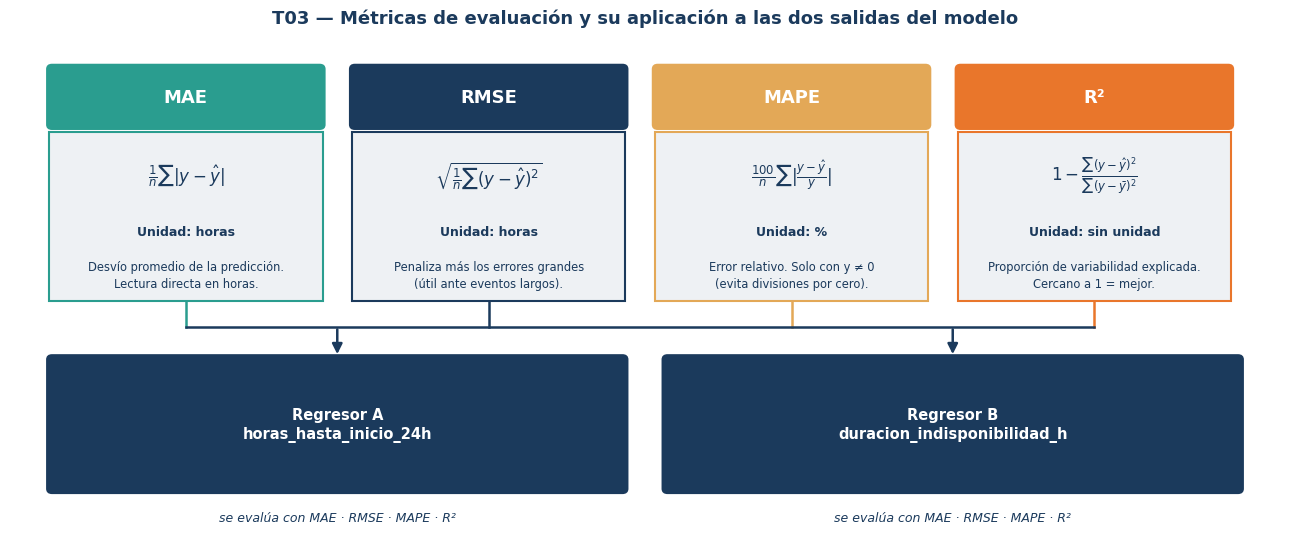

In [ ]:
# T03 - Vista visual de las metricas de evaluacion (definicion y aplicacion; sin datos)
tarjetas = [
    ('MAE',  r'$\frac{1}{n}\sum |y-\hat{y}|$',        'horas',  'Desvío promedio de la predicción.\nLectura directa en horas.',            COLOR_TEAL),
    ('RMSE', r'$\sqrt{\frac{1}{n}\sum (y-\hat{y})^2}$', 'horas',  'Penaliza más los errores grandes\n(útil ante eventos largos).',            COLOR_NAVY),
    ('MAPE', r'$\frac{100}{n}\sum |\frac{y-\hat{y}}{y}|$', '%',   'Error relativo. Solo con y \u2260 0\n(evita divisiones por cero).',        COLOR_GOLD),
    ('R²',   r'$1-\frac{\sum (y-\hat{y})^2}{\sum (y-\bar{y})^2}$', 'sin unidad', 'Proporción de variabilidad explicada.\nCercano a 1 = mejor.', COLOR_ORANGE),
]
fig, ax = lienzo(13, 5.6, xlim=(0, 13), ylim=(0, 5.9))
ax.set_title('T03 — Métricas de evaluación y su aplicación a las dos salidas del modelo',
             fontsize=13, color=COLOR_NAVY, fontweight='bold', pad=2)

for k, (nombre, formula, unidad, lectura, color) in enumerate(tarjetas):
    x = 0.4 + k * 3.1
    caja(ax, x, 4.75, 2.8, 0.7, nombre, color=color, fontsize=13)
    ax.add_patch(Rectangle((x, 2.75), 2.8, 1.95, facecolor=COLOR_GRAY_LT, edgecolor=color, lw=1.5, zorder=1))
    ax.text(x + 1.4, 4.2, formula, ha='center', va='center', fontsize=12, color=COLOR_NAVY, zorder=3)
    ax.text(x + 1.4, 3.55, f'Unidad: {unidad}', ha='center', va='center', fontsize=9, color=COLOR_NAVY, fontweight='bold', zorder=3)
    ax.text(x + 1.4, 3.05, lectura, ha='center', va='center', fontsize=8.3, color=COLOR_NAVY, zorder=3, linespacing=1.4)
    ax.plot([x + 1.4, x + 1.4], [2.75, 2.45], color=color, lw=1.8, zorder=1)
ax.plot([1.8, 11.1], [2.45, 2.45], color=COLOR_NAVY, lw=1.8, zorder=1)
flecha(ax, (3.35, 2.45), (3.35, 2.1))
flecha(ax, (9.65, 2.45), (9.65, 2.1))

salidas = [('Regresor A\nhoras_hasta_inicio_24h', 0.4), ('Regresor B\nduracion_indisponibilidad_h', 6.7)]
for texto, x in salidas:
    caja(ax, x, 0.55, 5.9, 1.55, texto, color=COLOR_NAVY, fontsize=10.5)
    ax.text(x + 2.95, 0.25, 'se evalúa con MAE · RMSE · MAPE · R²', ha='center', va='center',
            fontsize=9, color=COLOR_NAVY, style='italic')
plt.tight_layout()
plt.show()

### Definition of Done — HU02 (T03)

| Tarea | Criterio de aceptación | Estado |
|---|---|---|
| T03 | MAE definido e implementado | **CUMPLE** |
| T03 | RMSE definido e implementado | **CUMPLE** |
| T03 | MAPE definido e implementado, excluyendo valores reales iguales a cero | **CUMPLE** |
| T03 | R² definido e implementado | **CUMPLE** |
| T03 | Función reutilizable `calcular_metricas_regresion` | **CUMPLE** |
| T03 | Aplicación definida para `horas_hasta_inicio_24h` y `duracion_indisponibilidad_h` | **CUMPLE** |
| T03 | Evidencia visual de la definición y aplicación de las métricas | **CUMPLE** |
| T03 | Evaluación con las predicciones reales de los modelos GBM | **PENDIENTE — fase de Modelado** |
| T03 | Evaluación mediante validación temporal definitiva | **PENDIENTE — fase de Modelado** |

> **Resultado de la HU02:** las métricas de evaluación quedan definidas y preparadas para ser utilizadas con los datos reales del Terminal Portuario ENGIE-Ilo, manteniendo la separación entre la definición de métricas y la evaluación final del modelo.


## 2.3 HU03 — Integración de fuentes de datos

**Historia de usuario:** *Como investigador, quiero integrar las fuentes de datos meteorológicas, oceanográficas y el histórico de indisponibilidad operativa en una malla horaria común, para disponer de un dataset unificado que sirva de insumo a HU04 (Análisis exploratorio) y HU05 (Limpieza).*

**Tareas de esta HU:**
- **T04** — Importar datos meteorológicos (velocidad y dirección del viento, temperatura, humedad relativa, presión atmosférica).
- **T05** — Importar datos oceanográficos (altura de olas).
- **T06** — Integrar el histórico de indisponibilidad operativa con las variables meteo-oceanográficas.

**Regla de integración aplicada (inciso e del diseño del pipeline):** cada variable llega en un archivo independiente, con su propia frecuencia y sin sincronización entre sensores. Por eso la integración se hace en dos pasos: (1) se remuestrea **cada variable por separado** a la malla horaria común, estandarizando unidades antes de agregar, y (2) recién entonces se **unen** los resultados horarios ya agregados — nunca se hace un `merge` directo por timestamp exacto entre los crudos.

**Antes de ejecutar:** sube a la sesión de Colab (panel de archivos, o Google Drive) los 9 archivos (la celda siguiente te pedirá subir los que falten):
- `Velocidad de Viento-data-2025-05-23 a 2026-08-12.csv`
- `Direccion de Viento-data-2025-05-23 a 2026-08-12.csv`
- `Temperatura-data-2025-05-23 a 2026-08-12.csv`
- `Humedad Relativa-data-2025-05-23 a 2026-08-12.csv`
- `Presion Atmosferica-data-2025-05-23 a 2026-08-12.csv`
- `Altura de Olas-data-2025-05-23 a 2026-08-12.csv`
- `Temperatura Interna de Datalogger-data-2025-05-23 a 2026-08-12.csv`
- `Voltaje de Datalogger-data-2025-05-23 a 2026-08-12.csv`
- `Historico_Indisponibilidad_Operativa-2024-01-01_a_2026-08-12.csv`


### Configuración común de importación

In [ ]:
# ==== HU03 - Configuracion comun de importacion ====
import glob
import re
import os
from pathlib import Path

# Si se ejecuta en Google Colab y faltan archivos, se ofrece subirlos desde el equipo.
# Si ya estan en el directorio de trabajo (o se ejecuta fuera de Colab), no hace nada.
PATRONES_REQUERIDOS = [
    'Velocidad de Viento*.csv', 'Direccion de Viento*.csv', 'Temperatura-*.csv',
    'Humedad Relativa*.csv', 'Presion Atmosferica*.csv', 'Altura de Olas*.csv',
    'Temperatura Interna de Datalogger*.csv', 'Voltaje de Datalogger*.csv',
    'Historico_Indisponibilidad_Operativa*.csv',
]
faltantes = [p for p in PATRONES_REQUERIDOS if not glob.glob(p)]
if faltantes:
    try:
        from google.colab import files
        print('Faltan archivos; selecciona los CSV a subir:', *faltantes, sep='\n  - ')
        files.upload()
    except ImportError:
        print('Aviso: faltan archivos en el directorio de trabajo:', *faltantes, sep='\n  - ')

# Patrones de archivo (glob) -> nombre tecnico de columna.
# Se usan patrones, no nombres exactos, porque en produccion el datalogger
# agrega la fecha/hora de exportacion al nombre del archivo (ver ejemplo real
# del enunciado: 'Velocidad de Viento-data-2026-07-03 17_01_21.csv').
ARCHIVOS_METEOROLOGICOS = {
    'velocidad_viento_mph':    'Velocidad de Viento*.csv',
    'direccion_viento_deg':    'Direccion de Viento*.csv',
    'temperatura_c':           'Temperatura-*.csv',
    'humedad_relativa_pct':    'Humedad Relativa*.csv',
    'presion_atmosferica_hpa': 'Presion Atmosferica*.csv',
}

ARCHIVOS_OCEANOGRAFICOS = {
    'altura_olas_m': 'Altura de Olas*.csv',
}

# Variables de diagnostico del datalogger: NO son variables meteo-oceanograficas
# (no estan en `fuentes_datos` de HU01/T02), pero se importan igual porque
# ayudan a explicar vacios prolongados compartidos (ej. bateria baja -> apagon).
ARCHIVOS_DIAGNOSTICO = {
    'temperatura_interna_datalogger_c': 'Temperatura Interna de Datalogger*.csv',
    'voltaje_datalogger_v':             'Voltaje de Datalogger*.csv',
}

ARCHIVO_HISTORICO_INDISPONIBILIDAD = 'Historico_Indisponibilidad_Operativa*.csv'


def cargar_variable_cruda(patron_archivo, nombre_columna):
    '''Importa un CSV crudo del datalogger (formato Time,"columna").

    No corrige la calidad del dato (eso es HU05); solo lo deja en un tipo
    utilizable (datetime + float) y REPORTA lo que encontro: timestamps
    invalidos, celdas vacias y texto no parseable (p. ej. 'ERROR', 'N/A',
    '#VALUE!', o numeros con coma decimal).

    Retorna (df, reporte).
    '''
    coincidencias = glob.glob(patron_archivo)
    if not coincidencias:
        raise FileNotFoundError(
            f'No se encontro ningun archivo que coincida con el patron {patron_archivo!r}. '
            'Sube el archivo a la sesion de Colab antes de ejecutar esta celda.'
        )
    ruta = coincidencias[0]

    df = pd.read_csv(ruta, encoding='utf-8')
    df.columns = ['Time', 'valor_crudo']
    n_original = len(df)

    df['fecha_hora'] = pd.to_datetime(df['Time'], errors='coerce')
    n_fecha_invalida = int(df['fecha_hora'].isna().sum())
    n_valor_vacio_original = int(df['valor_crudo'].isna().sum())

    def extraer_numero(v):
        if pd.isna(v):
            return np.nan
        s = str(v).strip().replace(',', '.')
        m = re.search(r'-?\d+(\.\d+)?', s)
        return float(m.group()) if m else np.nan

    df[nombre_columna] = df['valor_crudo'].apply(extraer_numero)
    n_no_parseable = int(df[nombre_columna].isna().sum()) - n_valor_vacio_original

    reporte = {
        'variable': nombre_columna,
        'archivo': Path(ruta).name,
        'filas_leidas': n_original,
        'timestamps_invalidos': n_fecha_invalida,
        'valores_vacios_originales': n_valor_vacio_original,
        'texto_no_parseable': max(n_no_parseable, 0),
        'primer_registro': df['fecha_hora'].min(),
        'ultimo_registro': df['fecha_hora'].max(),
    }
    return df[['fecha_hora', nombre_columna]], reporte


### 2.3.1 T04 — Importar datos meteorológicos

Se importan las 5 variables meteorológicas definidas como predictores en HU01/T02 (`velocidad_viento_mph`, `direccion_viento_deg`, `temperatura_c`, `humedad_relativa_pct`, `presion_atmosferica_hpa`), más las 2 variables de diagnóstico del datalogger (`temperatura_interna_datalogger_c`, `voltaje_datalogger_v`), que no son predictores del modelo pero se conservan porque explican fallas compartidas entre sensores (por ejemplo, una caída de voltaje coincide con un vacío prolongado en todas las variables).

In [ ]:
# ==== T04 - Carga de variables meteorologicas ====
datos_meteo_crudos = {}
reportes_meteo = []

for columna, patron in ARCHIVOS_METEOROLOGICOS.items():
    df_var, reporte = cargar_variable_cruda(patron, columna)
    datos_meteo_crudos[columna] = df_var
    reportes_meteo.append(reporte)

for columna, patron in ARCHIVOS_DIAGNOSTICO.items():
    df_var, reporte = cargar_variable_cruda(patron, columna)
    datos_meteo_crudos[columna] = df_var
    reportes_meteo.append(reporte)

reporte_importacion_meteo = pd.DataFrame(reportes_meteo)
display(reporte_importacion_meteo)

,variable,archivo,filas_leidas,timestamps_invalidos,valores_vacios_originales,texto_no_parseable,primer_registro,ultimo_registro
0,velocidad_viento_mph,Velocidad de Viento-data-2025-05-23_a_2026-08-12.csv,128736,0,4832,0,2025-05-23,2026-08-12 23:55:00
1,direccion_viento_deg,Direccion de Viento-data-2025-05-23_a_2026-08-12.csv,128736,0,4832,0,2025-05-23,2026-08-12 23:55:00
2,temperatura_c,Temperatura-data-2025-05-23_a_2026-08-12.csv,128736,0,4830,0,2025-05-23,2026-08-12 23:55:00
3,humedad_relativa_pct,Humedad Relativa-data-2025-05-23_a_2026-08-12.csv,128736,0,4831,0,2025-05-23,2026-08-12 23:55:00
4,presion_atmosferica_hpa,Presion Atmosferica-data-2025-05-23_a_2026-08-12.csv,128736,0,4828,0,2025-05-23,2026-08-12 23:55:00
5,temperatura_interna_datalogger_c,Temperatura Interna de Datalogger-data-2025-05-23_a_2026-08-12.csv,128736,0,4831,0,2025-05-23,2026-08-12 23:55:00
6,voltaje_datalogger_v,Voltaje de Datalogger-data-2025-05-23_a_2026-08-12.csv,128736,0,4831,0,2025-05-23,2026-08-12 23:55:00


### 2.3.2 T05 — Importar datos oceanográficos

El sensor de oleaje es un **registro independiente**, con su propia hora de inicio y sus propios vacíos de mantenimiento (no coincide con los de los sensores meteorológicos, tal como señala el inciso e del diseño del pipeline). Se importa por separado con la misma función, para dejar explícito que su tratamiento de calidad (T08/T09) puede diferir del de las variables meteorológicas.

In [ ]:
# ==== T05 - Carga de la variable oceanografica ====
datos_oceano_crudos = {}
reportes_oceano = []

for columna, patron in ARCHIVOS_OCEANOGRAFICOS.items():
    df_var, reporte = cargar_variable_cruda(patron, columna)
    datos_oceano_crudos[columna] = df_var
    reportes_oceano.append(reporte)

reporte_importacion_oceano = pd.DataFrame(reportes_oceano)
display(reporte_importacion_oceano)

,variable,archivo,filas_leidas,timestamps_invalidos,valores_vacios_originales,texto_no_parseable,primer_registro,ultimo_registro
0,altura_olas_m,Altura de Olas-data-2025-05-23_a_2026-08-12.csv,128736,0,7673,0,2025-05-23,2026-08-12 23:55:00


### 2.3.3 T06 — Integrar historiales de indisponibilidad operativa

#### 2.3.3.1 Deduplicación y remuestreo a la malla horaria común (inciso a y e del pipeline)

Antes de unir las variables se aplican, en orden, las reglas del diseño del pipeline:

1. **Deduplicación** por marca de tiempo repetida, conservando la última lectura válida (inciso f).
2. **Remuestreo horario**: promedio para variables continuas; **media circular** para la dirección del viento, porque promediar grados directamente es incorrecto cerca del salto 360°→0° (p. ej. promediar 350° y 10° debe dar 0°, no 180°).
3. **Estandarización de unidades**: se agrega `velocidad_viento_ms` (mph → m/s) para ser consistente con la literatura del Estado del Arte, sin descartar la columna original en mph.

In [ ]:
# ==== Deduplicacion + remuestreo horario (aplica a T04 y T05 por igual) ====
MPH_A_MS = 0.44704


def limpiar_duplicados_por_timestamp(df, col):
    '''Deduplicacion previa a la agregacion (inciso f): conserva la ultima
    lectura valida cuando la marca de tiempo se repite.'''
    return (df.dropna(subset=['fecha_hora'])
              .sort_values('fecha_hora')
              .drop_duplicates(subset='fecha_hora', keep='last'))


def media_circular_grados(valores):
    '''Media circular en grados (0-360), usada para direccion_viento_deg.'''
    rad = np.deg2rad(valores.dropna())
    if len(rad) == 0:
        return np.nan
    return float(np.degrees(np.arctan2(np.sin(rad).mean(), np.cos(rad).mean())) % 360)


def remuestrear_a_hora(df, col, circular=False):
    df = limpiar_duplicados_por_timestamp(df, col).set_index('fecha_hora')
    if circular:
        return df[col].resample('h').apply(media_circular_grados)
    return df[col].resample('h').mean()


series_horarias = {}
conteo_dedup = []

for col, df_crudo in {**datos_meteo_crudos, **datos_oceano_crudos}.items():
    n_antes = len(df_crudo)
    circular = (col == 'direccion_viento_deg')
    df_dedup = limpiar_duplicados_por_timestamp(df_crudo, col)
    series_horarias[col] = remuestrear_a_hora(df_crudo, col, circular=circular)
    conteo_dedup.append({
        'variable': col,
        'lecturas_crudas': n_antes,
        'lecturas_tras_dedup': len(df_dedup),
        'duplicados_eliminados': n_antes - len(df_dedup),
        'horas_con_dato_tras_remuestreo': int(series_horarias[col].notna().sum()),
    })

# Estandarizacion de unidades (inciso e): mph -> m/s, sin perder la columna original
series_horarias['velocidad_viento_ms'] = series_horarias['velocidad_viento_mph'] * MPH_A_MS

reporte_remuestreo = pd.DataFrame(conteo_dedup)
display(reporte_remuestreo)

,variable,lecturas_crudas,lecturas_tras_dedup,duplicados_eliminados,horas_con_dato_tras_remuestreo
0,velocidad_viento_mph,128736,128736,0,10608
1,direccion_viento_deg,128736,128736,0,10608
2,temperatura_c,128736,128736,0,10608
3,humedad_relativa_pct,128736,128736,0,10608
4,presion_atmosferica_hpa,128736,128736,0,10608
5,temperatura_interna_datalogger_c,128736,128736,0,10608
6,voltaje_datalogger_v,128736,128736,0,10608
7,altura_olas_m,128736,128736,0,10560


#### 2.3.3.2 Malla horaria común e importación del histórico de indisponibilidad

Una vez remuestreadas las variables de T04 y T05, se construye la **malla horaria común** (unión de todas las variables ya remuestreadas) y se ubica cada serie sobre ella. Después se importa el histórico de indisponibilidad donde se el T06 es una tarea de *integración estructural*, no de limpieza (eso es HU05 / T09-T10).

In [ ]:
# ==== Malla horaria comun e integracion de variables meteo-oceanograficas ====
malla_horaria = pd.date_range(
    min(s.index.min() for s in series_horarias.values()),
    max(s.index.max() for s in series_horarias.values()),
    freq='h',
)

df_integrado_horario = pd.DataFrame(index=malla_horaria)
df_integrado_horario.index.name = 'fecha_hora'
for col, serie in series_horarias.items():
    df_integrado_horario[col] = serie.reindex(malla_horaria)

print(f'Malla horaria comun: {malla_horaria.min()} -> {malla_horaria.max()}  '
      f'({len(malla_horaria)} horas)')
display(df_integrado_horario.head())

Malla horaria comun: 2025-05-23 00:00:00 -> 2026-08-12 23:00:00  (10728 horas)


,velocidad_viento_mph,direccion_viento_deg,temperatura_c,humedad_relativa_pct,presion_atmosferica_hpa,temperatura_interna_datalogger_c,voltaje_datalogger_v,altura_olas_m,velocidad_viento_ms
fecha_hora,,,,,,,,,
2025-05-23 00:00:00,8.280000,221.657597,16.672500,91.816667,1015.425833,19.240000,13.763333,1.807500,3.701491
2025-05-23 01:00:00,8.424000,224.811596,14.916000,90.282000,1013.136000,21.149000,13.804000,1.281000,3.765865
2025-05-23 02:00:00,8.815000,225.951875,16.473333,90.340000,1014.753333,19.656667,13.833333,1.085000,3.940658
2025-05-23 03:00:00,7.259091,251.251220,15.585455,91.316364,1015.098182,18.628182,13.820000,1.118182,3.245104
2025-05-23 04:00:00,7.798182,211.734637,15.031818,91.073636,1014.518182,18.550909,13.819091,1.454545,3.486099


In [ ]:
# ==== T06 - Importacion cruda del historico de indisponibilidad (sin limpiar) ====
ruta_eventos = glob.glob(ARCHIVO_HISTORICO_INDISPONIBILIDAD)[0]
df_eventos_crudo = pd.read_csv(ruta_eventos, parse_dates=['fecha_inicio', 'fecha_fin'])

duracion_calculada = (df_eventos_crudo['fecha_fin'] - df_eventos_crudo['fecha_inicio']) / pd.Timedelta(hours=1)
inconsistencia_duracion = (duracion_calculada - df_eventos_crudo['duracion_h_registrada']).abs() > 0.05

inventario_calidad_eventos = pd.DataFrame([
    ['Filas totales en el historico', len(df_eventos_crudo)],
    ['id_evento duplicados (mismo evento digitado 2 veces)', int(df_eventos_crudo['id_evento'].duplicated().sum())],
    ['fecha_fin nula (evento en curso al exportar)', int(df_eventos_crudo['fecha_fin'].isna().sum())],
    ['fecha_fin < fecha_inicio (fechas invertidas)', int((df_eventos_crudo['fecha_fin'] < df_eventos_crudo['fecha_inicio']).sum())],
    ['duracion_h_registrada no coincide con fin-inicio', int(inconsistencia_duracion.sum())],
    ['variantes de formato en variable_dominante', int(df_eventos_crudo['variable_dominante'].nunique())],
], columns=['Hallazgo de calidad (a resolver en HU05 / T09-T10)', 'Cantidad'])

print(f'Historico importado desde: {Path(ruta_eventos).name}')
display(df_eventos_crudo.head())
display(inventario_calidad_eventos)

Historico importado desde: Historico_Indisponibilidad_Operativa-2024-01-01_a_2026-08-12.csv


,id_evento,fecha_inicio,fecha_fin,oleaje_max_durante_evento_m,viento_max_durante_evento_mph,direccion_predominante_durante_evento_deg,temperatura_media_durante_evento_c,humedad_media_durante_evento_pct,presion_media_durante_evento_hpa,variable_dominante,causa_registrada,fuente_registro,duracion_h_calculada,duracion_h_registrada
0,EV001,2024-01-09 23:41:27,2024-01-10 01:59:27,3.47,12.42,221.5,20.79,75.20,1012.28,OLEAJE,Altura de olas por encima del umbral operativo de maniobra,Bitácora Centro de Control Operativo,2.30,2.30
1,EV002,2024-01-20 16:15:37,2024-01-20 18:55:13,1.54,25.83,98.1,23.75,88.45,1016.33,VIENTO,Velocidad de viento por encima del umbral operativo de maniobra,Bitácora Centro de Control Operativo,2.66,2.66
2,EV003,2024-01-21 16:49:36,2024-01-21 20:52:36,2.60,22.10,84.7,10.84,97.20,1014.95,VIENTO,Velocidad de viento por encima del umbral operativo de maniobra,Bitácora Centro de Control Operativo,4.05,4.05
3,EV004,2024-01-27 11:46:25,2024-01-27 15:59:37,2.75,14.71,185.4,17.14,80.31,1004.43,no meteo-oceanografica,Falla mecánica de equipo de amarre,Bitácora Centro de Control Operativo,4.22,4.22
4,EV005,2024-02-09 17:27:42,2024-02-09 22:27:42,4.51,27.66,304.8,25.92,67.28,1014.43,Oleaje,Altura de olas por encima del umbral operativo de maniobra,Bitácora Centro de Control Operativo,5.00,5.00


,Hallazgo de calidad (a resolver en HU05 / T09-T10),Cantidad
0,Filas totales en el historico,259
1,id_evento duplicados (mismo evento digitado 2 veces),4
2,fecha_fin nula (evento en curso al exportar),3
3,fecha_fin < fecha_inicio (fechas invertidas),3
4,duracion_h_registrada no coincide con fin-inicio,10
5,variantes de formato en variable_dominante,13


#### 2.3.3.3 Integración del histórico con la malla horaria y construcción de las etiquetas

**Nota metodológica:** para integrar de punta a punta en esta misma HU (unir el histórico con la malla horaria y reutilizar `construir_targets_evento`, definida en 2.1.2.7) se usa un subconjunto de eventos **bien formados** (sin fechas nulas ni invertidas, sin ids duplicados). Este filtro es **mínimo y provisional**: **no reemplaza** la limpieza formal de T09/T10 (HU05), que deberá decidir cómo tratar cada caso (¿se corrige la fecha invertida o se descarta el evento?, ¿se imputa la `fecha_fin` del evento en curso o se excluye?).

In [ ]:
# ==== T06 - Integracion provisional historico + malla horaria (filtro minimo, end-to-end) ====
eventos_bien_formados_provisional = (
    df_eventos_crudo
    .dropna(subset=['fecha_inicio', 'fecha_fin'])
    .drop_duplicates(subset='id_evento')
)
eventos_bien_formados_provisional = eventos_bien_formados_provisional[
    eventos_bien_formados_provisional['fecha_fin'] > eventos_bien_formados_provisional['fecha_inicio']
].reset_index(drop=True)

print(f'Eventos crudos: {len(df_eventos_crudo)}  ->  '
      f'Eventos bien formados usados para la integracion (filtro provisional): {len(eventos_bien_formados_provisional)}')

# Reutiliza construir_targets_evento(), definida en HU01 (T02), sobre la malla horaria de HU03
targets_horarios = construir_targets_evento(
    timestamps=df_integrado_horario.index,
    df_eventos=eventos_bien_formados_provisional,
    horizonte_h=24,
).set_index('t')

df_integrado_horario['ocurre_evento_24h'] = targets_horarios['ocurre_evento_24h'].values
df_integrado_horario['horas_hasta_inicio_24h'] = targets_horarios['horas_hasta_inicio_24h'].values
df_integrado_horario['duracion_indisponibilidad_h'] = targets_horarios['duracion_indisponibilidad_h'].values

display(df_integrado_horario[['velocidad_viento_ms', 'altura_olas_m', 'ocurre_evento_24h',
                               'horas_hasta_inicio_24h', 'duracion_indisponibilidad_h']].head(10))

Eventos crudos: 259  ->  Eventos bien formados usados para la integracion (filtro provisional): 249


,velocidad_viento_ms,altura_olas_m,ocurre_evento_24h,horas_hasta_inicio_24h,duracion_indisponibilidad_h
fecha_hora,,,,,
2025-05-23 00:00:00,3.701491,1.807500,0,NaN,NaN
2025-05-23 01:00:00,3.765865,1.281000,0,NaN,NaN
2025-05-23 02:00:00,3.940658,1.085000,0,NaN,NaN
2025-05-23 03:00:00,3.245104,1.118182,0,NaN,NaN
2025-05-23 04:00:00,3.486099,1.454545,0,NaN,NaN
2025-05-23 05:00:00,2.602518,1.065833,0,NaN,NaN
2025-05-23 06:00:00,2.626360,1.192500,0,NaN,NaN
2025-05-23 07:00:00,2.464816,1.090909,0,NaN,NaN
2025-05-23 08:00:00,3.444443,1.294545,0,NaN,NaN


**Vista visual — cobertura horaria integrada, con los eventos de indisponibilidad superpuestos:**

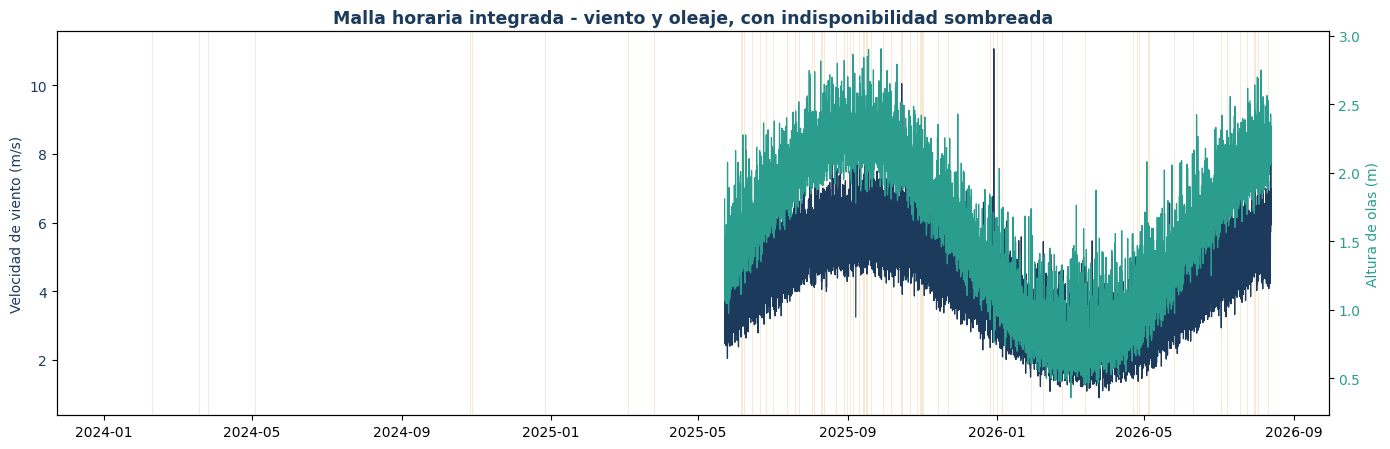

In [ ]:
# ==== Vista visual: viento y oleaje horarios, con eventos de indisponibilidad sombreados ====
fig, ax1 = plt.subplots(figsize=(14, 4.6))

ax1.plot(df_integrado_horario.index, df_integrado_horario['velocidad_viento_ms'],
         color=COLOR_NAVY, lw=0.9, label='Viento (m/s)')
ax1.set_ylabel('Velocidad de viento (m/s)', color=COLOR_NAVY)
ax1.tick_params(axis='y', labelcolor=COLOR_NAVY)

ax2 = ax1.twinx()
ax2.plot(df_integrado_horario.index, df_integrado_horario['altura_olas_m'],
         color=COLOR_TEAL, lw=0.9, label='Oleaje (m)')
ax2.set_ylabel('Altura de olas (m)', color=COLOR_TEAL)
ax2.tick_params(axis='y', labelcolor=COLOR_TEAL)

for _, ev in eventos_bien_formados_provisional.iterrows():
    ax1.axvspan(ev['fecha_inicio'], ev['fecha_fin'], color=COLOR_GOLD, alpha=0.25, lw=0)

ax1.set_title('Malla horaria integrada - viento y oleaje, con indisponibilidad sombreada',
              fontsize=12.5, color=COLOR_NAVY, fontweight='bold')
fig.tight_layout()
plt.show()

#### 2.3.3.4 Cobertura y exportación del dataset unificado

In [ ]:
# ==== Reporte de cobertura del dataset integrado (T06) ====
cobertura = pd.DataFrame({
    'columna': df_integrado_horario.columns,
    'horas_con_dato': df_integrado_horario.notna().sum().values,
    'horas_totales': len(df_integrado_horario),
})
cobertura['pct_completitud'] = (100 * cobertura['horas_con_dato'] / cobertura['horas_totales']).round(1)
display(cobertura)

# Exporta el dataset integrado horario, insumo directo de HU04 (EDA) y HU05 (limpieza)
df_integrado_horario.to_csv('dataset_integrado_horario_HU03.csv')
print('Guardado: dataset_integrado_horario_HU03.csv')

,columna,horas_con_dato,horas_totales,pct_completitud
0,velocidad_viento_mph,10608,10728,98.9
1,direccion_viento_deg,10608,10728,98.9
2,temperatura_c,10608,10728,98.9
3,humedad_relativa_pct,10608,10728,98.9
4,presion_atmosferica_hpa,10608,10728,98.9
5,temperatura_interna_datalogger_c,10608,10728,98.9
6,voltaje_datalogger_v,10608,10728,98.9
7,altura_olas_m,10560,10728,98.4
8,velocidad_viento_ms,10608,10728,98.9
9,ocurre_evento_24h,10728,10728,100.0


Guardado: dataset_integrado_horario_HU03.csv


### Definition of Done — HU03 (T04 / T05 / T06)

In [ ]:
dod_hu03 = pd.DataFrame([
    ['T04', 'Las 5 variables meteorologicas se importan desde su CSV crudo con conteo de fallas de parseo', 'CUMPLE'],
    ['T04', 'Variables de diagnostico del datalogger (temp. interna, voltaje) importadas para explicar vacios compartidos', 'CUMPLE'],
    ['T05', 'La variable oceanografica se importa de forma independiente, sin asumir sincronia con los sensores meteorologicos', 'CUMPLE'],
    ['-', 'Deduplicacion por timestamp antes de agregar (inciso f)', 'CUMPLE'],
    ['-', 'Remuestreo a malla horaria comun: media para variables continuas, media circular para direccion', 'CUMPLE'],
    ['-', 'Estandarizacion de unidades (mph -> m/s) antes de la integracion', 'CUMPLE'],
    ['T06', 'Historico de indisponibilidad importado sin alterar sus inconsistencias', 'CUMPLE'],
    ['T06', 'Inventario de calidad del historico documentado (insumo directo de T09/T10)', 'CUMPLE'],
    ['T06', 'Integracion end-to-end demostrada reutilizando construir_targets_evento() de HU01', 'CUMPLE'],
    ['T06', 'Dataset integrado horario exportado como insumo de HU04/HU05', 'CUMPLE'],
    ['-', 'Limpieza de nulos/duplicados/outliers e inconsistencias de fecha-duracion', 'PENDIENTE (HU05, T09-T10)'],
], columns=['Tarea', 'Criterio de aceptacion', 'Estado'])

display(dod_hu03)

,Tarea,Criterio de aceptacion,Estado
0,T04,Las 5 variables meteorologicas se importan desde su CSV crudo con conteo de fallas de parseo,CUMPLE
1,T04,"Variables de diagnostico del datalogger (temp. interna, voltaje) importadas para explicar vacios compartidos",CUMPLE
2,T05,"La variable oceanografica se importa de forma independiente, sin asumir sincronia con los sensores meteorologicos",CUMPLE
3,-,Deduplicacion por timestamp antes de agregar (inciso f),CUMPLE
4,-,"Remuestreo a malla horaria comun: media para variables continuas, media circular para direccion",CUMPLE
5,-,Estandarizacion de unidades (mph -> m/s) antes de la integracion,CUMPLE
6,T06,Historico de indisponibilidad importado sin alterar sus inconsistencias,CUMPLE
7,T06,Inventario de calidad del historico documentado (insumo directo de T09/T10),CUMPLE
8,T06,Integracion end-to-end demostrada reutilizando construir_targets_evento() de HU01,CUMPLE
9,T06,Dataset integrado horario exportado como insumo de HU04/HU05,CUMPLE


## 2.4 HU04 — Análisis exploratorio de datos

Esta historia de usuario trabaja directamente sobre `df_integrado_horario`, el dataset horario unificado que exportó HU03 (T04-T06). **Todavía no se limpia nada aquí** (eso es HU05, T09-T10): el objetivo de HU04 es *entender* el dato tal como llegó — su distribución, su estructura de correlación/autocorrelación, y diagnosticar huecos y outliers — para que las decisiones de limpieza e ingeniería de características (HU05/HU06) estén basadas en evidencia y no en supuestos.

### 2.4.1 T07 — Realizar análisis descriptivo y correlacional

#### 2.4.1.1 Estadística descriptiva de las variables meteo-oceanográficas

In [ ]:
# ==== T07.1 - Estadistica descriptiva ====
VARIABLES_METEO_OCEANO = [
    'velocidad_viento_ms', 'direccion_viento_deg', 'temperatura_c',
    'humedad_relativa_pct', 'presion_atmosferica_hpa', 'altura_olas_m',
    'temperatura_interna_datalogger_c', 'voltaje_datalogger_v',
]

descriptivos = df_integrado_horario[VARIABLES_METEO_OCEANO].describe(
    percentiles=[.05, .25, .5, .75, .95]
).T
descriptivos['asimetria'] = df_integrado_horario[VARIABLES_METEO_OCEANO].skew()
descriptivos['curtosis'] = df_integrado_horario[VARIABLES_METEO_OCEANO].kurt()
descriptivos = descriptivos.round(2)
display(descriptivos)


,count,mean,std,min,5%,25%,50%,75%,95%,max,asimetria,curtosis
velocidad_viento_ms,10608.0,4.32,1.36,0.89,2.04,3.31,4.37,5.35,6.46,11.07,-0.05,-0.66
direccion_viento_deg,10608.0,204.94,23.42,137.44,167.67,186.59,205.17,223.05,242.08,301.80,0.01,-0.72
temperatura_c,10608.0,18.11,2.56,9.16,13.92,16.22,18.09,19.90,22.53,24.94,0.08,-0.68
humedad_relativa_pct,10608.0,83.60,6.16,66.47,73.57,78.11,84.53,88.92,92.13,96.58,-0.26,-1.11
presion_atmosferica_hpa,10608.0,1012.82,2.90,1004.66,1008.18,1010.05,1013.40,1015.41,1016.55,1020.39,-0.29,-1.24
altura_olas_m,10560.0,1.56,0.54,0.36,0.69,1.08,1.61,2.04,2.33,2.90,-0.16,-1.17
temperatura_interna_datalogger_c,10608.0,20.73,2.35,14.76,16.95,18.97,20.65,22.45,24.79,26.76,0.11,-0.78
voltaje_datalogger_v,10608.0,13.80,0.07,13.05,13.64,13.80,13.82,13.84,13.86,14.02,-3.46,16.13


**Vista visual — distribución por variable:**

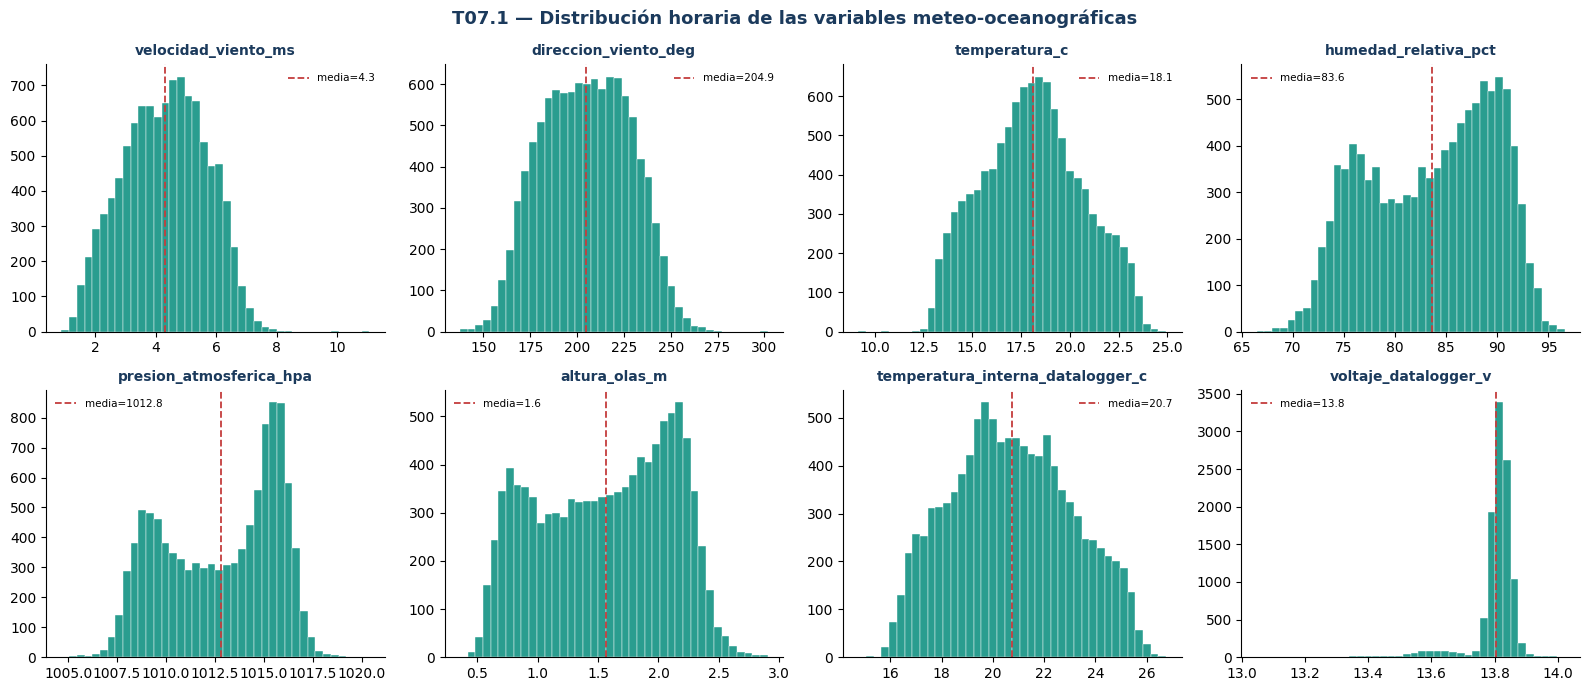

In [ ]:
# ==== T07.1 - Histogramas por variable ====
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), VARIABLES_METEO_OCEANO):
    datos = df_integrado_horario[col].dropna()
    ax.hist(datos, bins=40, color=COLOR_TEAL, edgecolor='white', linewidth=0.3)
    ax.axvline(datos.mean(), color=COLOR_RED, lw=1.3, ls='--', label=f'media={datos.mean():.1f}')
    ax.set_title(col, fontsize=10, color=COLOR_NAVY, fontweight='bold')
    ax.legend(fontsize=7.5, frameon=False)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('T07.1 — Distribución horaria de las variables meteo-oceanográficas',
             fontsize=13, color=COLOR_NAVY, fontweight='bold')
fig.tight_layout()
plt.show()


#### 2.4.1.2 Matriz de correlación (Pearson)

Incluye las 8 variables meteo-oceanográficas junto con las dos variables objetivo (`horas_hasta_inicio_24h`, `duracion_indisponibilidad_h`) **solo para explorar relación**, nunca como predictor de sí misma — estas dos columnas no entran como X en el modelo (Q07 de HU01).

In [ ]:
# ==== T07.2 - Matriz de correlacion ====
COLUMNAS_CORR = VARIABLES_METEO_OCEANO + ['horas_hasta_inicio_24h', 'duracion_indisponibilidad_h']
matriz_corr = df_integrado_horario[COLUMNAS_CORR].corr(method='pearson').round(2)
display(matriz_corr)

# Pares con correlacion relevante (|r| > 0.3), excluyendo la diagonal
pares = (
    matriz_corr.where(np.triu(np.ones(matriz_corr.shape), k=1).astype(bool))
    .stack()
    .rename('r')
    .reset_index()
    .rename(columns={'level_0': 'variable_1', 'level_1': 'variable_2'})
)
pares_relevantes = pares[pares['r'].abs() > 0.3].sort_values('r', key=abs, ascending=False)
print(f'Pares con |r| > 0.3 encontrados: {len(pares_relevantes)}')
display(pares_relevantes.reset_index(drop=True))


,velocidad_viento_ms,direccion_viento_deg,temperatura_c,humedad_relativa_pct,presion_atmosferica_hpa,altura_olas_m,temperatura_interna_datalogger_c,voltaje_datalogger_v,horas_hasta_inicio_24h,duracion_indisponibilidad_h
velocidad_viento_ms,1.00,-0.67,0.72,-0.42,0.30,0.86,0.67,0.01,-0.05,-0.03
direccion_viento_deg,-0.67,1.00,-0.57,0.58,-0.05,-0.72,-0.62,0.01,0.02,0.01
temperatura_c,0.72,-0.57,1.00,-0.78,-0.29,0.50,0.95,0.00,-0.01,-0.02
humedad_relativa_pct,-0.42,0.58,-0.78,1.00,0.58,-0.31,-0.82,0.01,0.02,0.02
presion_atmosferica_hpa,0.30,-0.05,-0.29,0.58,1.00,0.47,-0.32,0.01,-0.01,0.01
altura_olas_m,0.86,-0.72,0.50,-0.31,0.47,1.00,0.51,0.00,-0.06,-0.02
temperatura_interna_datalogger_c,0.67,-0.62,0.95,-0.82,-0.32,0.51,1.00,0.00,-0.01,-0.02
voltaje_datalogger_v,0.01,0.01,0.00,0.01,0.01,0.00,0.00,1.00,-0.00,0.01
horas_hasta_inicio_24h,-0.05,0.02,-0.01,0.02,-0.01,-0.06,-0.01,-0.00,1.00,-0.01
duracion_indisponibilidad_h,-0.03,0.01,-0.02,0.02,0.01,-0.02,-0.02,0.01,-0.01,1.00


Pares con |r| > 0.3 encontrados: 18


,variable_1,variable_2,r
0,temperatura_c,temperatura_interna_datalogger_c,0.95
1,velocidad_viento_ms,altura_olas_m,0.86
2,humedad_relativa_pct,temperatura_interna_datalogger_c,-0.82
3,temperatura_c,humedad_relativa_pct,-0.78
4,direccion_viento_deg,altura_olas_m,-0.72
5,velocidad_viento_ms,temperatura_c,0.72
6,velocidad_viento_ms,direccion_viento_deg,-0.67
7,velocidad_viento_ms,temperatura_interna_datalogger_c,0.67
8,direccion_viento_deg,temperatura_interna_datalogger_c,-0.62
9,direccion_viento_deg,humedad_relativa_pct,0.58


**Vista visual — mapa de calor de correlaciones:**

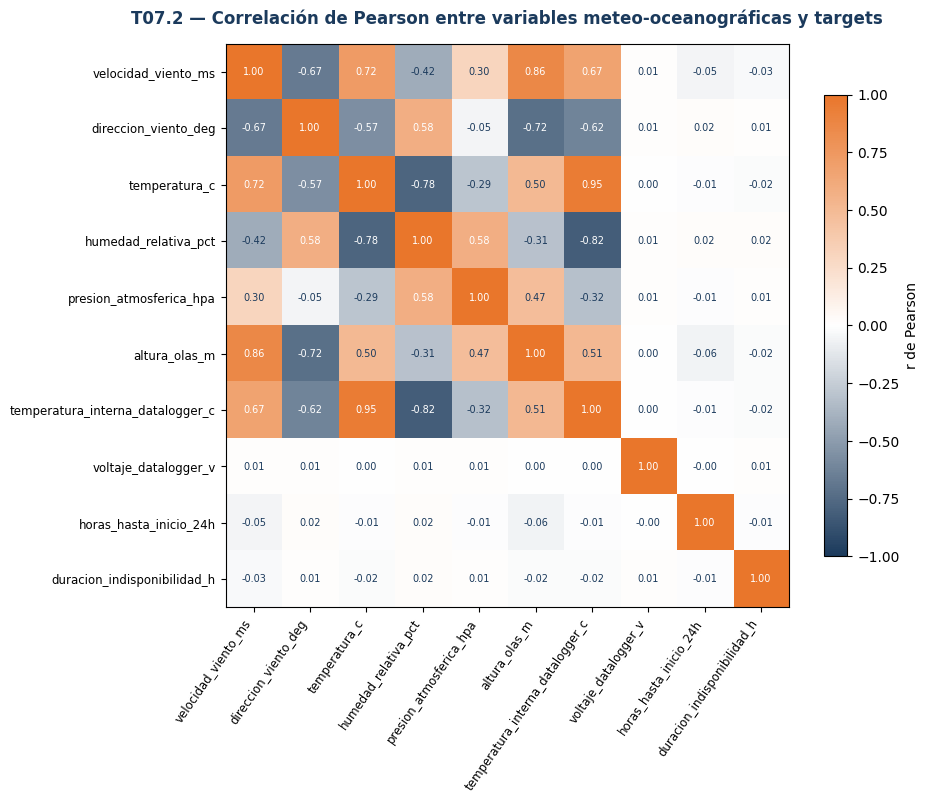

In [ ]:
# ==== T07.2 - Heatmap de correlacion ====
from matplotlib.colors import LinearSegmentedColormap
cmap_corr = LinearSegmentedColormap.from_list('navy_teal_orange', [COLOR_NAVY, 'white', COLOR_ORANGE])

fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(matriz_corr.values, cmap=cmap_corr, vmin=-1, vmax=1)
ax.set_xticks(range(len(matriz_corr.columns)))
ax.set_xticklabels(matriz_corr.columns, rotation=55, ha='right', fontsize=8.5)
ax.set_yticks(range(len(matriz_corr.columns)))
ax.set_yticklabels(matriz_corr.columns, fontsize=8.5)
for i in range(matriz_corr.shape[0]):
    for j in range(matriz_corr.shape[1]):
        v = matriz_corr.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center',
                fontsize=7, color='white' if abs(v) > 0.55 else COLOR_NAVY)
ax.set_title('T07.2 — Correlación de Pearson entre variables meteo-oceanográficas y targets',
             fontsize=12, color=COLOR_NAVY, fontweight='bold', pad=14)
fig.colorbar(im, ax=ax, shrink=0.8, label='r de Pearson')
fig.tight_layout()
plt.show()


#### 2.4.1.3 Autocorrelación por variable (insumo directo para los rezagos de HU06/T12)

En nuestro trabajo de investigacion se  define los rezagos t-1, t-2, t-3, t-6, t-12 y t-24 (inciso g del pipeline). Antes de darlos por buenos, se revisa aquí si la autocorrelación real de cada variable respalda justamente esos horizontes.

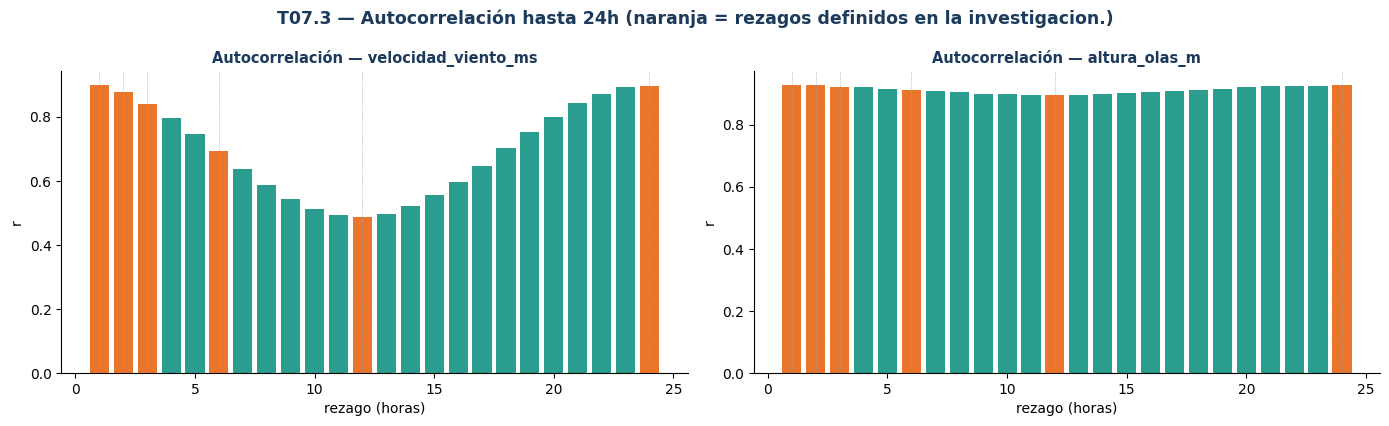

Autocorrelacion exactamente en los rezagos definidos:


,velocidad_viento_ms,altura_olas_m
t-1,0.898,0.926
t-2,0.877,0.926
t-3,0.840,0.922
t-6,0.692,0.912
t-12,0.488,0.895
t-24,0.894,0.927


In [ ]:
# ==== T07.3 - Autocorrelacion hasta 24h ====
def autocorrelacion_hasta(serie, max_lag=24):
    s = serie.dropna()
    return [s.autocorr(lag=k) for k in range(1, max_lag + 1)]

LAGS_TF = [1, 2, 3, 6, 12, 24]
variables_clave = ['velocidad_viento_ms', 'altura_olas_m']

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
tabla_acf = {}
for ax, col in zip(axes, variables_clave):
    acf = autocorrelacion_hasta(df_integrado_horario[col], max_lag=24)
    tabla_acf[col] = acf
    colores = [COLOR_ORANGE if (k + 1) in LAGS_TF else COLOR_TEAL for k in range(24)]
    ax.bar(range(1, 25), acf, color=colores)
    for lag in LAGS_TF:
        ax.axvline(lag, color=COLOR_GRAY, lw=0.6, ls=':')
    ax.set_title(f'Autocorrelación — {col}', fontsize=10.5, color=COLOR_NAVY, fontweight='bold')
    ax.set_xlabel('rezago (horas)')
    ax.set_ylabel('r')
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('T07.3 — Autocorrelación hasta 24h (naranja = rezagos definidos en la investigacion.)',
             fontsize=12.5, color=COLOR_NAVY, fontweight='bold')
fig.tight_layout()
plt.show()

resumen_acf = pd.DataFrame(
    {col: [tabla_acf[col][k-1] for k in LAGS_TF] for col in variables_clave},
    index=[f't-{k}' for k in LAGS_TF]
).round(3)
print('Autocorrelacion exactamente en los rezagos definidos:')
display(resumen_acf)


#### 2.4.1.4 Condiciones meteo-oceanográficas en horas con y sin indisponibilidad próxima

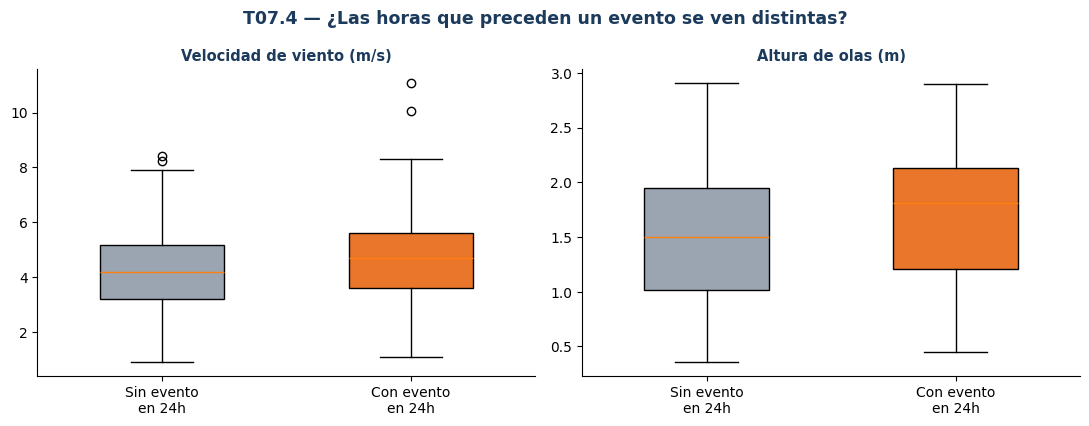

In [ ]:
# ==== T07.4 - Viento y oleaje segun ocurre_evento_24h ====
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, col, titulo in zip(
    axes,
    ['velocidad_viento_ms', 'altura_olas_m'],
    ['Velocidad de viento (m/s)', 'Altura de olas (m)'],
):
    datos = [
        df_integrado_horario.loc[df_integrado_horario['ocurre_evento_24h'] == 0, col].dropna(),
        df_integrado_horario.loc[df_integrado_horario['ocurre_evento_24h'] == 1, col].dropna(),
    ]
    bp = ax.boxplot(datos, tick_labels=['Sin evento\nen 24h', 'Con evento\nen 24h'],
                     patch_artist=True, widths=0.5)
    for patch, color in zip(bp['boxes'], [COLOR_GRAY, COLOR_ORANGE]):
        patch.set_facecolor(color)
    ax.set_title(titulo, fontsize=10.5, color=COLOR_NAVY, fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('T07.4 — ¿Las horas que preceden un evento se ven distintas?',
             fontsize=12.5, color=COLOR_NAVY, fontweight='bold')
fig.tight_layout()
plt.show()


### 2.4.2 T08 — Identificar valores faltantes y outliers

**Alcance de T08: solo identificar y documentar.** El tratamiento (imputación, recorte/transformación de outliers) es T09-T10 en HU05 — a propósito no se modifica ningún valor en esta sección.

#### 2.4.2.1 Vacíos por variable y huecos más largos (relevante para elegir interpolación lineal vs. spline en T09)

In [ ]:
# ==== T08.1 - Completitud y huecos (gaps) por variable ====
def diagnosticar_vacios(serie):
    '''Cuenta vacios totales y la racha de NaN consecutivos mas larga (en horas).'''
    es_nulo = serie.isna()
    grupos = (es_nulo != es_nulo.shift()).cumsum()
    rachas = es_nulo.groupby(grupos).sum()
    racha_max = int(rachas.max()) if es_nulo.any() else 0
    return {
        'variable': serie.name,
        'horas_totales': len(serie),
        'horas_vacias': int(es_nulo.sum()),
        'pct_vacio': round(100 * es_nulo.mean(), 2),
        'racha_maxima_horas': racha_max,
    }

diagnostico_vacios = pd.DataFrame(
    [diagnosticar_vacios(df_integrado_horario[c]) for c in VARIABLES_METEO_OCEANO]
).sort_values('pct_vacio', ascending=False).reset_index(drop=True)
display(diagnostico_vacios)

print(
    'Sugerencia que consideramos para T09: con rachas de pocas horas, interpolacion lineal es suficiente; '
    'donde la racha maxima supera ~6-12h seguidas, conviene spline o dejar el hueco sin '
    'imputar si excede el umbral que defina HU05.'
)


,variable,horas_totales,horas_vacias,pct_vacio,racha_maxima_horas
0,altura_olas_m,10728,168,1.57,12
1,velocidad_viento_ms,10728,120,1.12,9
2,temperatura_c,10728,120,1.12,9
3,direccion_viento_deg,10728,120,1.12,9
4,humedad_relativa_pct,10728,120,1.12,9
5,presion_atmosferica_hpa,10728,120,1.12,9
6,temperatura_interna_datalogger_c,10728,120,1.12,9
7,voltaje_datalogger_v,10728,120,1.12,9


Sugerencia que consideramos para T09: con rachas de pocas horas, interpolacion lineal es suficiente; donde la racha maxima supera ~6-12h seguidas, conviene spline o dejar el hueco sin imputar si excede el umbral que defina HU05.


#### 2.4.2.2 Detección de outliers por rango intercuartílico (IQR)

In [ ]:
# ==== T08.2 - Deteccion de outliers (IQR) ====
def detectar_outliers_iqr(serie, k=1.5):
    '''Identifica outliers por la regla de Tukey. No los elimina ni los corrige (T09).'''
    s = serie.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    limite_inf, limite_sup = q1 - k * iqr, q3 + k * iqr
    es_outlier = (s < limite_inf) | (s > limite_sup)
    return {
        'variable': serie.name,
        'limite_inferior': round(limite_inf, 2),
        'limite_superior': round(limite_sup, 2),
        'n_outliers': int(es_outlier.sum()),
        'pct_outliers': round(100 * es_outlier.mean(), 2),
    }

reporte_outliers = pd.DataFrame(
    [detectar_outliers_iqr(df_integrado_horario[c]) for c in VARIABLES_METEO_OCEANO]
).sort_values('pct_outliers', ascending=False).reset_index(drop=True)
display(reporte_outliers)


,variable,limite_inferior,limite_superior,n_outliers,pct_outliers
0,voltaje_datalogger_v,13.74,13.90,852,8.03
1,velocidad_viento_ms,0.24,8.41,2,0.02
2,temperatura_c,10.71,25.41,2,0.02
3,direccion_viento_deg,131.91,277.74,1,0.01
4,humedad_relativa_pct,61.88,105.15,0,0.00
5,presion_atmosferica_hpa,1001.99,1023.47,0,0.00
6,altura_olas_m,-0.35,3.47,0,0.00
7,temperatura_interna_datalogger_c,13.75,27.67,0,0.00


**Vista visual — boxplots con los límites de Tukey:**

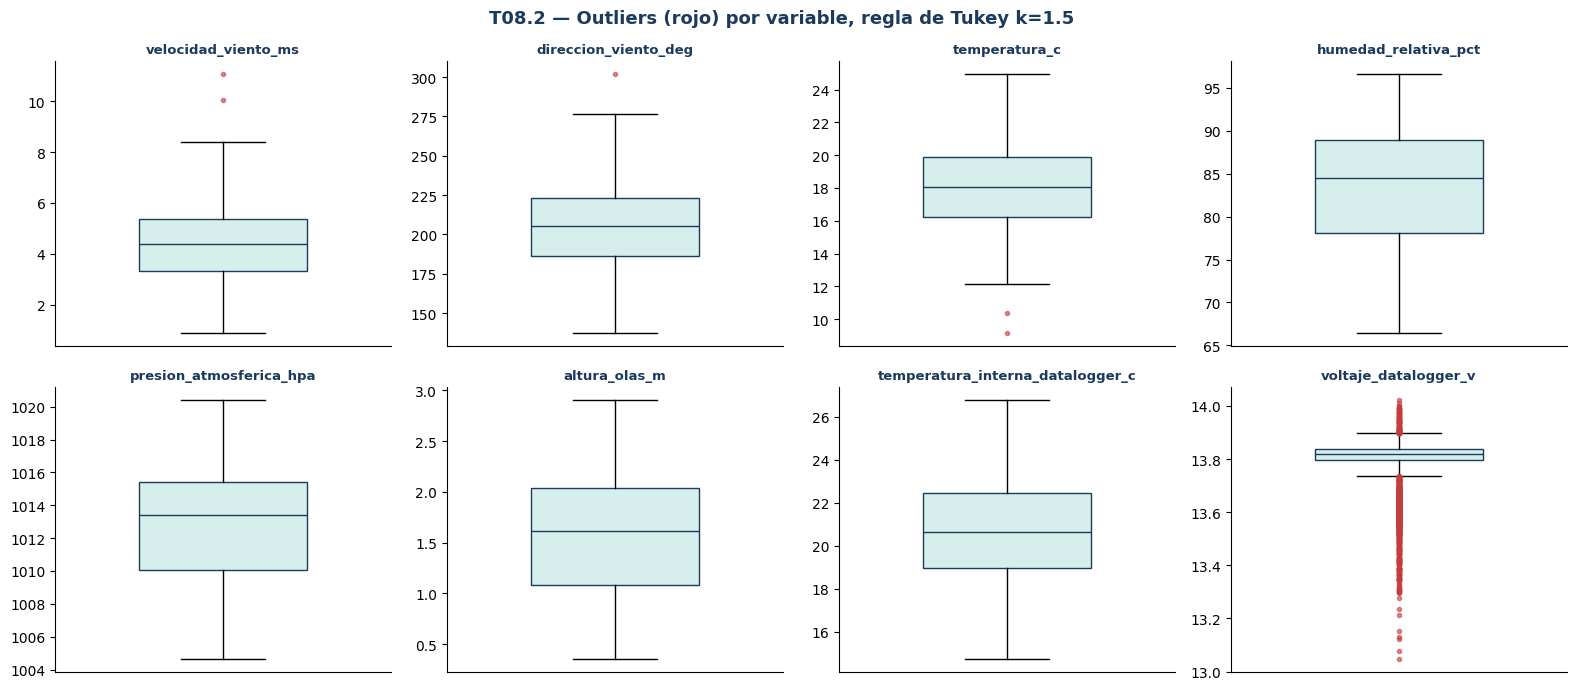

In [ ]:
# ==== T08.2 - Boxplots por variable ====
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), VARIABLES_METEO_OCEANO):
    datos = df_integrado_horario[col].dropna()
    bp = ax.boxplot(datos, patch_artist=True, widths=0.5, flierprops={
        'markerfacecolor': COLOR_RED, 'markeredgecolor': COLOR_RED, 'markersize': 3, 'alpha': 0.6})
    bp['boxes'][0].set_facecolor(COLOR_TEAL_LT)
    bp['boxes'][0].set_edgecolor(COLOR_NAVY)
    bp['medians'][0].set_color(COLOR_NAVY)
    ax.set_title(col, fontsize=9.5, color=COLOR_NAVY, fontweight='bold')
    ax.set_xticks([])
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('T08.2 — Outliers (rojo) por variable, regla de Tukey k=1.5',
             fontsize=13, color=COLOR_NAVY, fontweight='bold')
fig.tight_layout()
plt.show()


### Definition of Done — HU04 (T07 / T08)

In [ ]:
# ==== HU04 - Definition of Done ====
dod_hu04 = pd.DataFrame([
    ['T07', 'Estadistica descriptiva (media, dispersion, asimetria, curtosis) de las 8 variables', 'CUMPLE'],
    ['T07', 'Matriz de correlacion de Pearson calculada y pares relevantes (|r|>0.3) identificados', 'CUMPLE'],
    ['T07', 'Autocorrelacion hasta 24h calculada para contrastar empiricamente los rezagos del TF (t-1..t-24)', 'CUMPLE'],
    ['T07', 'Comparacion de condiciones meteo-oceanograficas en horas con y sin evento proximo (24h)', 'CUMPLE'],
    ['T08', 'Vacios por variable cuantificados, incluyendo la racha de NaN consecutivos mas larga', 'CUMPLE'],
    ['T08', 'Outliers identificados por variable con el metodo IQR (Tukey), sin alterar el dato', 'CUMPLE'],
    ['-', 'Ningun valor fue imputado, eliminado ni corregido en esta historia (fuera de alcance de T07-T08)', 'CUMPLE'],
    ['-', 'Tratamiento de nulos/duplicados/outliers e inconsistencias de fecha-duracion', 'PENDIENTE (HU05, T09-T10)'],
], columns=['Tarea', 'Criterio de aceptacion', 'Estado'])

display(dod_hu04)


,Tarea,Criterio de aceptacion,Estado
0,T07,"Estadistica descriptiva (media, dispersion, asimetria, curtosis) de las 8 variables",CUMPLE
1,T07,Matriz de correlacion de Pearson calculada y pares relevantes (|r|>0.3) identificados,CUMPLE
2,T07,Autocorrelacion hasta 24h calculada para contrastar empiricamente los rezagos del TF (t-1..t-24),CUMPLE
3,T07,Comparacion de condiciones meteo-oceanograficas en horas con y sin evento proximo (24h),CUMPLE
4,T08,"Vacios por variable cuantificados, incluyendo la racha de NaN consecutivos mas larga",CUMPLE
5,T08,"Outliers identificados por variable con el metodo IQR (Tukey), sin alterar el dato",CUMPLE
6,-,"Ningun valor fue imputado, eliminado ni corregido en esta historia (fuera de alcance de T07-T08)",CUMPLE
7,-,Tratamiento de nulos/duplicados/outliers e inconsistencias de fecha-duracion,"PENDIENTE (HU05, T09-T10)"
